# Forecasting Petroleum Product Prices in Ghana

### A comparative evaluation of SARIMA, Random Forest, XGBoost and LSTM

---

**Data:** National Petroleum Authority (NPA) *Historical Trend of Petroleum
Products Prices*, 1989 - August 2026, together with the cedi/dollar reference
rate the NPA applies in each pricing window.

**What this notebook does**

1. Parses the NPA workbook into a clean monthly panel of prices and price components.
2. Establishes the statistical character of the series (trend, seasonality, stationarity, volatility).
3. Fits the four models in the thesis methodology on an identical information set.
4. Evaluates them against a random-walk benchmark with scale-free metrics and a
   Diebold-Mariano test, at one step ahead and across horizons 1-12.
5. Replicates the whole comparison across every product in the dataset.
6. Produces a 12-month ex-ante forecast and writes every figure and table to disk.

**How to re-run it for a different product:** change `PRIMARY_TARGET` in the
configuration cell. Nothing else needs editing.

## 0. Environment and configuration

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import npa_etl
import forecasting as fc
import thesis_viz as viz
from npa_etl import PRODUCT_LABELS, POLICY_FIELDS, product_columns

viz.setup_theme()
FIG_DIR = ROOT / "outputs" / "figures"
TBL_DIR = ROOT / "outputs" / "tables"
for d in (FIG_DIR, TBL_DIR, ROOT / "data" / "processed"):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: "%.4f" % v)

print("python     ", sys.version.split()[0])
print("pandas     ", pd.__version__)
print("numpy      ", np.__version__)
import sklearn, xgboost, statsmodels, torch
print("scikit-learn", sklearn.__version__)
print("xgboost    ", xgboost.__version__)
print("statsmodels", statsmodels.__version__)
print("torch      ", torch.__version__, "| CUDA:", torch.cuda.is_available())

python      3.13.5
pandas      2.2.3
numpy       2.3.5


scikit-learn 1.8.0
xgboost     3.1.3
statsmodels 0.14.6
torch       2.10.0+cpu | CUDA: False


In [2]:
# --------------------------------------------------------------------------
# Study configuration -- the only cell that normally needs editing
# --------------------------------------------------------------------------

PRIMARY_TARGET = "AGO_MINES_ghs"   # export-quoted gas oil (mines/rig), converted to GHS per litre
TARGET_LABEL = "Gas Oil (Mines/Rig) export-quoted price converted to GHS/L"

SEASON = 12          # monthly data
TEST_MONTHS = 24     # hold-out length for the headline comparison
MAX_HORIZON = 12     # horizons profiled in the multi-step analysis
N_ORIGINS = 24       # rolling origins in the multi-horizon study
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

# Market drivers: genuinely unknown at forecast time, so they enter lagged only.
MARKET_DRIVERS = [
    "fx_ghs_usd",            # cedi per US dollar, NPA reference rate
    "ATK_price",             # aviation turbine kerosene, USD/litre
    "MGO_FOREIGN_price",     # marine gasoil (foreign), USD/litre
    "AGO_MINES_EXP_price",   # gas oil mines/rig, USD/litre
    "RFO_price",             # residual fuel oil, GHS/litre
]

print("primary target :", PRIMARY_TARGET)
print("hold-out       :", TEST_MONTHS, "months")
print("horizons       : 1 -", MAX_HORIZON)

primary target : AGO_MINES_ghs
hold-out       : 24 months
horizons       : 1 - 12


## 1. Data ingestion

The NPA workbook is a human-formatted spreadsheet rather than a data file: a
banner, a merged product header, a field header, a units row, then the
observations, repeated with a different layout on each sheet. `src/npa_etl.py`
handles that - it forward-fills the merged product names across the header,
maps each `(product, field)` pair to a column, converts pesewas and US cents to
cedis and dollars, and stacks the sheets into one panel.

In [3]:
panel = npa_etl.build_panel(ROOT / "data")
npa_etl.save_panel(panel, ROOT / "data" / "processed")

windows = panel["wide"]      # NPA pricing-window frequency (1st and 16th)
monthly = panel["monthly"]   # month-end resample
coverage = panel["coverage"]

print("pricing windows :", windows.shape, "|", windows.index.min().date(), "->", windows.index.max().date())
print("monthly panel   :", monthly.shape)
coverage[["label", "series", "currency", "unit", "n_windows", "n_months", "first", "last"]]

pricing windows : (458, 47) | 2007-09-01 -> 2026-08-01
monthly panel   : (228, 47)


,label,series,currency,unit,n_windows,n_months,first,last
0,Residual Fuel Oil,RFO_price,GHS,per_litre,458,224,2007-09-01,2026-08-01
1,Premix,PREMIX_price,GHS,per_litre,435,212,2009-01-02,2026-08-01
2,Aviation Turbine Kerosene,ATK_price,USD,per_litre,383,188,2011-01-01,2026-08-01
3,Marine Gasoil (foreign),MGO_FOREIGN_price,USD,per_litre,383,188,2011-01-01,2026-08-01
4,Gasoil Mines/Rig (export),AGO_MINES_EXP_price,USD,per_litre,371,183,2011-01-01,2026-08-01
5,LPG,LPG_price,GHS,per_kg,188,90,2007-09-01,2015-06-16
6,Diesel (AGO),AGO_price,GHS,per_litre,188,90,2007-09-01,2015-06-16
7,Petrol (PMS),PMS_price,GHS,per_litre,188,90,2007-09-01,2015-06-16
8,Kerosene,KERO_price,GHS,per_litre,188,90,2007-09-01,2015-06-16
9,Marine Gasoil (local),MGO_LOCAL_price,GHS,per_litre,165,78,2009-01-02,2015-06-16


### 1.1 Data availability audit

The thesis proposal lists four data sources. Only one of them is present in
`data/`, and the notebook is explicit about that rather than silently
substituting: the modelling below uses what the repository actually contains.

In [4]:
audit = pd.DataFrame(
    [
        ("NPA", "Petroleum product prices & price components",
         "AVAILABLE", "Historical-Trend-of-Petroleum-Products-Prices ... .xlsx, 1989-2026"),
        ("Bank of Ghana", "Monthly USD/GHS reference rate",
         "AVAILABLE (embedded)", "Carried on every row of the NPA workbook; the rate the NPA itself applies"),
        ("Bank of Ghana", "Interbank FX time series",
         "NOT USABLE", "'Interbank FX Rates Historical.xlsx' holds 2 days (30-31 Dec 2025), not a series"),
        ("Ghana Statistical Service", "Monthly CPI / headline inflation",
         "MISSING", "Only one PDF bulletin (June 2012) is present - no monthly series to merge"),
        ("NPA", "Monthly consumption volumes (PMS / AGO / LPG)",
         "MISSING", "No volume file in data/ - consumption cannot be modelled from this repository"),
        ("NPA / CBOD", "Pricing formula regulations",
         "AVAILABLE (reference)", "LI 2186 PDF - documents the ex-refinery + taxes + margins build-up"),
    ],
    columns=["Source", "Variable", "Status", "Note"],
)
audit.style.hide(axis="index")

Source,Variable,Status,Note
NPA,Petroleum product prices & price components,AVAILABLE,"Historical-Trend-of-Petroleum-Products-Prices ... .xlsx, 1989-2026"
Bank of Ghana,Monthly USD/GHS reference rate,AVAILABLE (embedded),Carried on every row of the NPA workbook; the rate the NPA itself applies
Bank of Ghana,Interbank FX time series,NOT USABLE,"'Interbank FX Rates Historical.xlsx' holds 2 days (30-31 Dec 2025), not a series"
Ghana Statistical Service,Monthly CPI / headline inflation,MISSING,Only one PDF bulletin (June 2012) is present - no monthly series to merge
NPA,Monthly consumption volumes (PMS / AGO / LPG),MISSING,No volume file in data/ - consumption cannot be modelled from this repository
NPA / CBOD,Pricing formula regulations,AVAILABLE (reference),LI 2186 PDF - documents the ex-refinery + taxes + margins build-up


**Consequence for the study design.** Consumption volumes and the CPI series
are absent, so the dependent variable is the **price** of a petroleum product,
not its consumed volume, and inflation cannot enter as a regressor. The
exchange rate survives, because the NPA records the rate it applied in each
pricing window. If the GSS CPI series and the NPA volume series are obtained
later, they join the panel on the month index and the rest of the notebook
runs unchanged.

## 2. Panel construction

Three of the long series are quoted in US cents per litre because they are
export-parity products. Multiplying by the NPA's own reference rate expresses
them in cedis per litre. The converted Gas Oil (Mines/Rig) series remains an
export-quoted price indicator; it is not the domestic consumer diesel price.

In [5]:
panel_m = monthly.copy()
# Convert each export-quoted price using the NPA reference FX rate recorded
# for that same pricing window, then average the converted values by month.
# Multiplying monthly mean price by monthly mean FX would not, in general,
# equal the mean of the window-level converted prices.
panel_w = windows.copy()
for p in ["ATK", "MGO_FOREIGN", "AGO_MINES_EXP"]:
    col = p + "_price"
    if col in panel_w.columns:
        converted_col = p.replace("_EXP", "") + "_ghs"
        panel_w[converted_col] = panel_w[col] * panel_w["fx_ghs_usd"]
        panel_m[converted_col] = panel_w[converted_col].resample("ME").mean().reindex(panel_m.index)

# Save a reproducible audit of zero-valued price quotes excluded by the ETL.
quality_audit = panel["quality_audit"].copy()
if not quality_audit.empty:
    quality_audit["date"] = pd.to_datetime(quality_audit["date"]).dt.strftime("%Y-%m-%d")
    special = quality_audit["date"].eq("2014-08-01") & quality_audit["product"].eq("AGO_MINES_EXP")
    if special.any():
        aug_value = panel_m.loc[pd.Timestamp("2014-08-31"), "AGO_MINES_ghs"]
        quality_audit.loc[special, "effect"] = (
            "Excluded before monthly averaging; August 2014 converted monthly value is "
            + f"GHS {aug_value:.4f}/L based on the positive pricing-window quote."
        )
    quality_audit.to_csv(TBL_DIR / "data_quality_audit.csv", index=False)

# A cedi-converted series carries the name of the product it was derived from,
# which is what the feature builder needs to find its price components.
GHS_BASE = {"AGO_MINES_ghs": "AGO_MINES_EXP", "MGO_FOREIGN_ghs": "MGO_FOREIGN",
            "ATK_ghs": "ATK"}

def base_product(col):
    return GHS_BASE.get(col, col.rsplit("_", 1)[0])

SERIES_LABELS = {
    "AGO_MINES_ghs": "Gas Oil (mines/rig), export-quoted, converted to GHS/L",
    "MGO_FOREIGN_ghs": "Marine Gas Oil, GHS/L",
    "ATK_ghs": "Aviation Kerosene, GHS/L",
    "AGO_MINES_EXP_price": "Gas Oil (mines/rig), USD/L",
    "MGO_FOREIGN_price": "Marine Gas Oil, USD/L",
    "ATK_price": "Aviation Kerosene, USD/L",
    "RFO_price": "Residual Fuel Oil, GHS/L",
    "PREMIX_price": "Premix, GHS/L",
    "PMS_price": "Petrol PMS ex-pump, GHS/L",
    "AGO_price": "Diesel AGO ex-pump, GHS/L",
    "LPG_price": "LPG ex-pump, GHS/kg",
    "KERO_price": "Kerosene ex-pump, GHS/L",
}

STUDY_SERIES = [s for s in SERIES_LABELS if s in panel_m.columns]
summary = pd.DataFrame({
    "label": [SERIES_LABELS[s] for s in STUDY_SERIES],
    "n_months": [int(panel_m[s].notna().sum()) for s in STUDY_SERIES],
    "first": [panel_m[s].first_valid_index() for s in STUDY_SERIES],
    "last": [panel_m[s].last_valid_index() for s in STUDY_SERIES],
    "mean": [panel_m[s].mean() for s in STUDY_SERIES],
    "sd": [panel_m[s].std() for s in STUDY_SERIES],
    "monthly_vol_%": [np.log(panel_m[s].dropna()).diff().std() * 100 for s in STUDY_SERIES],
}, index=STUDY_SERIES)
summary.sort_values("n_months", ascending=False)

,label,n_months,first,last,mean,sd,monthly_vol_%
RFO_price,"Residual Fuel Oil, GHS/L",224,2007-09-30,2026-08-31,2.6923,3.0794,9.4344
PREMIX_price,"Premix, GHS/L",212,2009-01-31,2026-08-31,2.0690,1.7244,8.4071
MGO_FOREIGN_ghs,"Marine Gas Oil, GHS/L",188,2011-01-31,2026-08-31,5.2634,4.2198,9.1957
ATK_ghs,"Aviation Kerosene, GHS/L",188,2011-01-31,2026-08-31,5.4230,4.5187,9.5467
ATK_price,"Aviation Kerosene, USD/L",188,2011-01-31,2026-08-31,0.8284,0.2679,8.3662
MGO_FOREIGN_price,"Marine Gas Oil, USD/L",188,2011-01-31,2026-08-31,0.8183,0.2515,7.7693
AGO_MINES_EXP_price,"Gas Oil (mines/rig), USD/L",183,2011-01-31,2026-08-31,0.7997,0.2461,7.9352
AGO_MINES_ghs,"Gas Oil (mines/rig), export-quoted, converted ...",183,2011-01-31,2026-08-31,5.2901,4.2818,9.5842
PMS_price,"Petrol PMS ex-pump, GHS/L",90,2007-09-30,2015-06-30,1.7340,0.7436,5.2660
AGO_price,"Diesel AGO ex-pump, GHS/L",90,2007-09-30,2015-06-30,1.7379,0.7189,5.0843


### 2.1 The primary series

In [6]:
own_cols = [c for c in product_columns(panel_m.columns, base_product(PRIMARY_TARGET))
            if c != PRIMARY_TARGET]
exog_cols = list(dict.fromkeys(own_cols + [c for c in MARKET_DRIVERS if c != PRIMARY_TARGET]))

data = fc.prepare_series(panel_m, PRIMARY_TARGET, exog_cols)
y = data[PRIMARY_TARGET]

print("series      :", SERIES_LABELS.get(PRIMARY_TARGET, PRIMARY_TARGET))
print("span        :", y.index.min().date(), "->", y.index.max().date(), "(%d months)" % len(y))
print("imputed     :", data.attrs["imputed_months"], "months with no NPA pricing window")
print("exogenous   :", [c for c in data.columns if c != PRIMARY_TARGET])
print()
y.describe().to_frame("value").T

series      : Gas Oil (mines/rig), export-quoted, converted to GHS/L
span        : 2011-01-31 -> 2026-08-31 (188 months)
imputed     : 5 months with no NPA pricing window
exogenous   : ['AGO_MINES_EXP_ex_ref', 'AGO_MINES_EXP_price', 'fx_ghs_usd', 'ATK_price', 'MGO_FOREIGN_price', 'RFO_price']



,count,mean,std,min,25%,50%,75%,max
value,188.0000,5.2275,4.2413,1.3650,2.2810,3.1427,8.6521,18.6168


## 3. Exploratory data analysis

### 3.1 The long-run picture

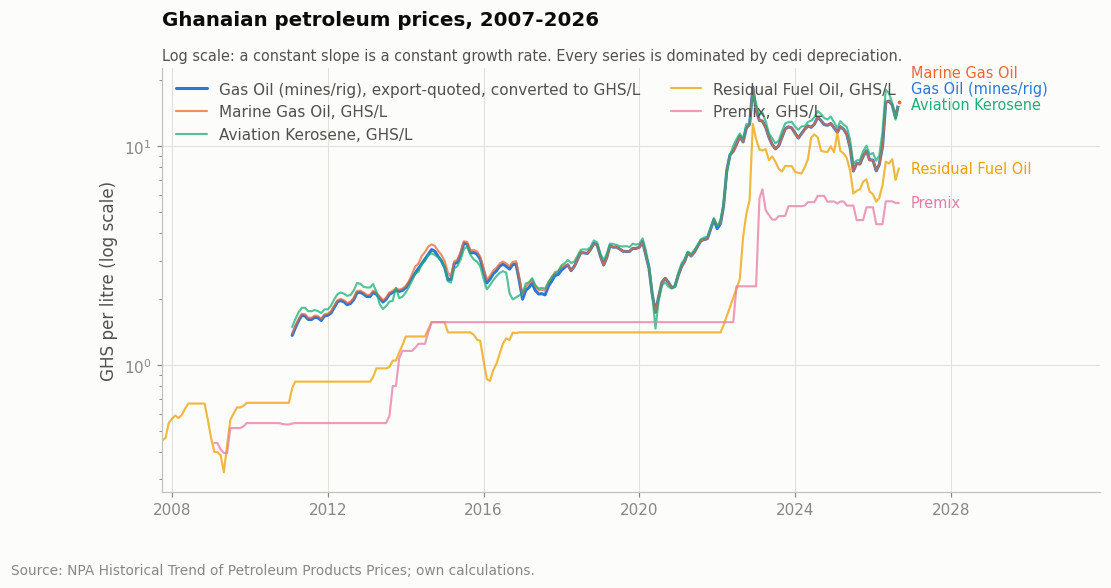

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
show = ["AGO_MINES_ghs", "MGO_FOREIGN_ghs", "ATK_ghs", "RFO_price", "PREMIX_price"]
show = [s for s in show if s in panel_m.columns]
end_labels = []
for i, s in enumerate(show):
    ser = panel_m[s].dropna()
    ax.plot(ser.index, ser.values, color=viz.CATEGORICAL[i], label=SERIES_LABELS[s],
            linewidth=2.0 if s == PRIMARY_TARGET else 1.4,
            alpha=1.0 if s == PRIMARY_TARGET else 0.75)
    end_labels.append((ser.index[-1], ser.iloc[-1], SERIES_LABELS[s].split(",")[0],
                       viz.CATEGORICAL[i]))
ax.set_yscale("log")
ax.set_ylabel("GHS per litre (log scale)")
ax.set_xlim(panel_m.index.min(), panel_m.index.max() + pd.DateOffset(months=62))
viz.titled(ax, "Ghanaian petroleum prices, 2007-2026",
           "Log scale: a constant slope is a constant growth rate. Every series is dominated by cedi depreciation.")
ax.legend(loc="upper left", ncol=2)
# Three of these five end within a few pesewas of each other, so the endpoint
# labels have to be separated explicitly or they overprint.
viz.label_ends(ax, end_labels, min_gap=16)
viz.annotate_source(fig, "Source: NPA Historical Trend of Petroleum Products Prices; own calculations.")
viz.save_fig(fig, "01_long_run_prices", FIG_DIR)
plt.show()

### 3.2 The primary series and its hold-out window

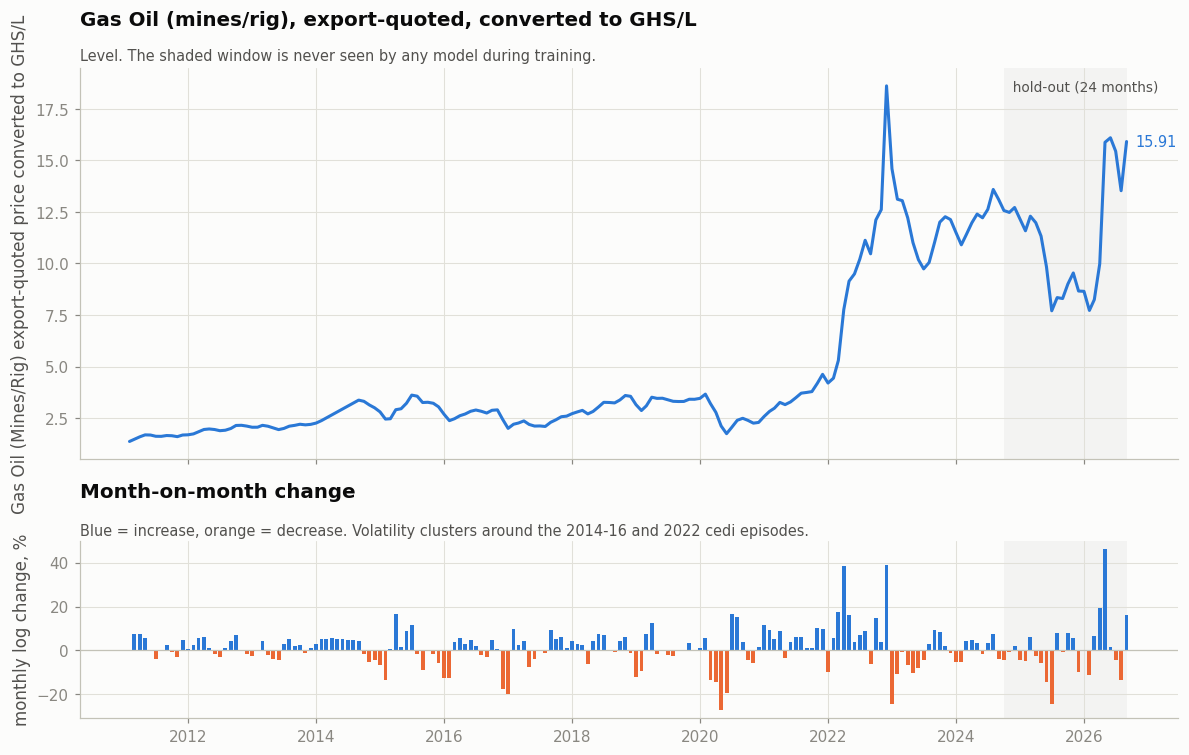

In [8]:
test_start_m = y.index[-TEST_MONTHS]

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                         gridspec_kw={"height_ratios": [2.2, 1]})
ax = axes[0]
ax.plot(y.index, y.values, color=viz.CATEGORICAL[0], linewidth=2.0)
viz.shade_span(ax, test_start_m, y.index[-1], "hold-out (%d months)" % TEST_MONTHS)
viz.label_end(ax, y.index[-1], y.iloc[-1], "%.2f" % y.iloc[-1], viz.CATEGORICAL[0])
ax.set_ylabel(TARGET_LABEL)
viz.titled(ax, SERIES_LABELS.get(PRIMARY_TARGET, PRIMARY_TARGET),
           "Level. The shaded window is never seen by any model during training.")

ax2 = axes[1]
r = np.log(y).diff() * 100
ax2.axhline(0, color=viz.INK["axis"], linewidth=0.8)
ax2.bar(r.index, r.values, width=22,
        color=np.where(r.values >= 0, viz.CATEGORICAL[0], viz.CATEGORICAL[1]))
viz.shade_span(ax2, test_start_m, y.index[-1])
ax2.set_ylabel("monthly log change, %")
viz.titled(ax2, "Month-on-month change",
           "Blue = increase, orange = decrease. Volatility clusters around the 2014-16 and 2022 cedi episodes.")
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
viz.save_fig(fig, "02_primary_series", FIG_DIR)
plt.show()

### 3.3 Exchange-rate pass-through

Two quantities on very different scales must never share a plot with two y-axes:
the alignment of the scales would invent a relationship. Both are indexed to
100 at the start of the sample and drawn on one axis instead.

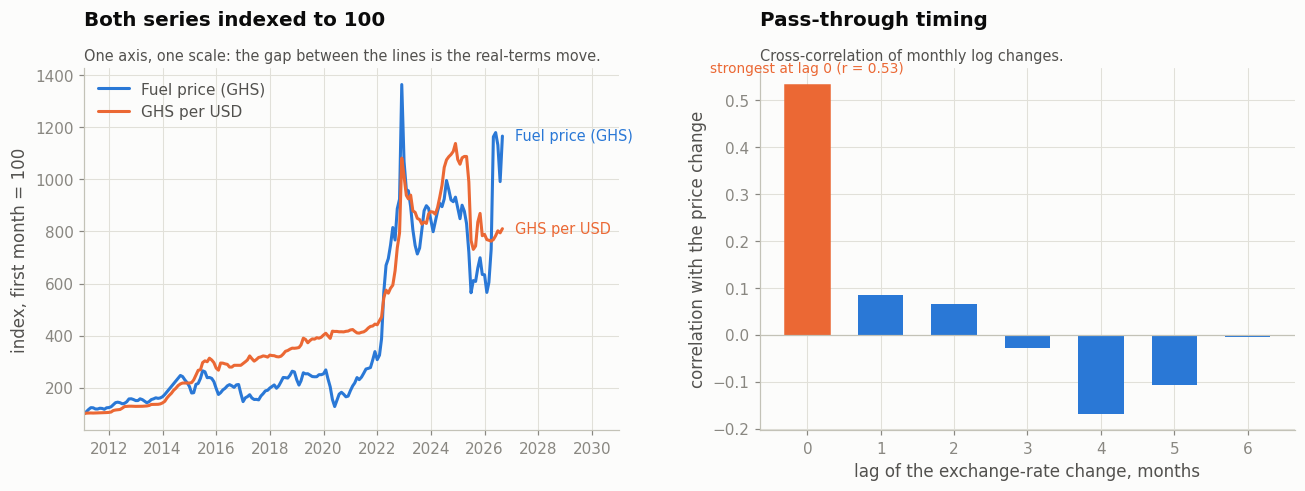

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]
base = data.loc[data.index[0]]
ends = []
for i, (col, name) in enumerate([(PRIMARY_TARGET, "Fuel price (GHS)"),
                                 ("fx_ghs_usd", "GHS per USD")]):
    idx = data[col] / base[col] * 100
    ax.plot(idx.index, idx.values, color=viz.CATEGORICAL[i], label=name)
    ends.append((idx.index[-1], idx.iloc[-1], name, viz.CATEGORICAL[i]))
ax.set_xlim(data.index[0], data.index[-1] + pd.DateOffset(months=52))
viz.label_ends(ax, ends)
ax.set_ylabel("index, first month = 100")
ax.legend(loc="upper left")
viz.titled(ax, "Both series indexed to 100",
           "One axis, one scale: the gap between the lines is the real-terms move.")

ax = axes[1]
dl_price = np.log(data[PRIMARY_TARGET]).diff()
dl_fx = np.log(data["fx_ghs_usd"]).diff()
lags = range(0, 7)
corrs = [dl_price.corr(dl_fx.shift(L)) for L in lags]
bars = ax.bar(list(lags), corrs, color=viz.CATEGORICAL[0], width=0.62)
best = int(np.nanargmax(np.abs(corrs)))
bars[best].set_color(viz.CATEGORICAL[1])
ax.annotate("strongest at lag %d (r = %.2f)" % (best, corrs[best]),
            xy=(best, corrs[best]), xytext=(0, 8), textcoords="offset points",
            ha="center", color=viz.CATEGORICAL[1], fontsize=9)
ax.axhline(0, color=viz.INK["axis"], linewidth=0.8)
ax.set_xlabel("lag of the exchange-rate change, months")
ax.set_ylabel("correlation with the price change")
viz.titled(ax, "Pass-through timing",
           "Cross-correlation of monthly log changes.")
fig.tight_layout()
viz.save_fig(fig, "03_fx_passthrough", FIG_DIR)
plt.show()

### 3.4 The pricing formula

LI 2186 builds the published price as *ex-refinery price + taxes and levies +
regulated margins*. Splitting the series that way shows which component
actually moves, and therefore what a forecasting model has to track.

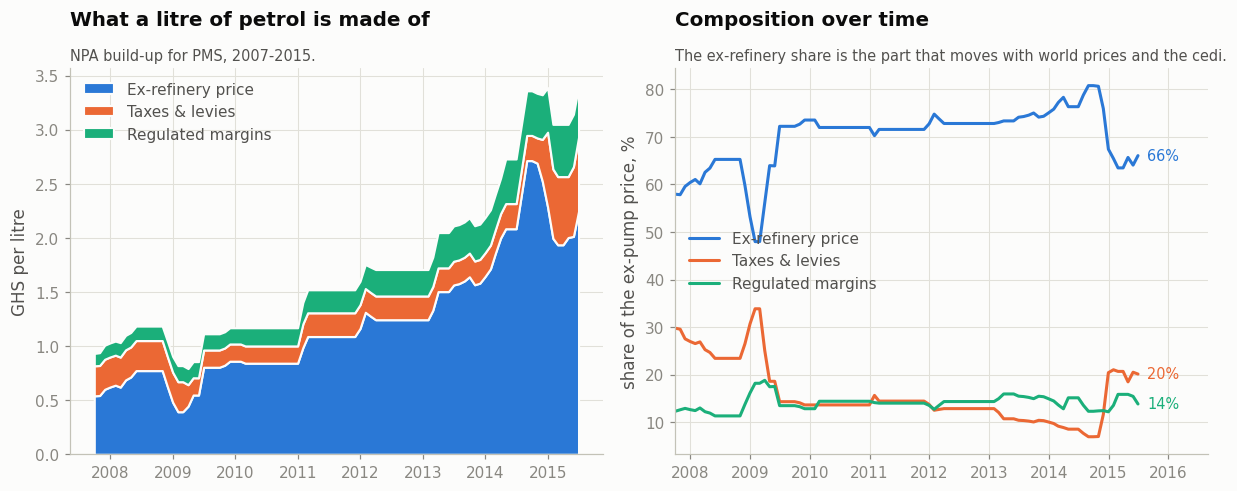

In [10]:
comp_product = "PMS"        # the domestic build-up is published in full for PMS
comp_cols = product_columns(monthly.columns, comp_product, ("ex_ref", "taxes", "margins"))
comp = monthly[comp_cols].dropna()

if len(comp):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    ax = axes[0]
    labels = ["Ex-refinery price", "Taxes & levies", "Regulated margins"]
    ax.stackplot(comp.index, [comp[c].values for c in comp_cols],
                 labels=labels, colors=[viz.CATEGORICAL[0], viz.CATEGORICAL[1], viz.CATEGORICAL[2]],
                 edgecolor=viz.INK["surface"], linewidth=1.4)
    ax.set_ylabel("GHS per litre")
    ax.legend(loc="upper left")
    viz.titled(ax, "What a litre of petrol is made of",
               "NPA build-up for PMS, %s-%s." % (comp.index[0].year, comp.index[-1].year))

    ax = axes[1]
    share = comp.div(comp.sum(axis=1), axis=0) * 100
    for i, (c, lab) in enumerate(zip(comp_cols, labels)):
        ax.plot(share.index, share[c].values, color=viz.CATEGORICAL[i], label=lab)
        viz.label_end(ax, share.index[-1], share[c].iloc[-1], "%.0f%%" % share[c].iloc[-1],
                      viz.CATEGORICAL[i])
    ax.set_ylabel("share of the ex-pump price, %")
    ax.set_xlim(share.index[0], share.index[-1] + pd.DateOffset(months=14))
    ax.legend(loc="center left")
    viz.titled(ax, "Composition over time",
               "The ex-refinery share is the part that moves with world prices and the cedi.")
    fig.tight_layout()
    viz.save_fig(fig, "04_pricing_formula", FIG_DIR)
    plt.show()

## 4. Time-series diagnostics

### 4.1 STL decomposition

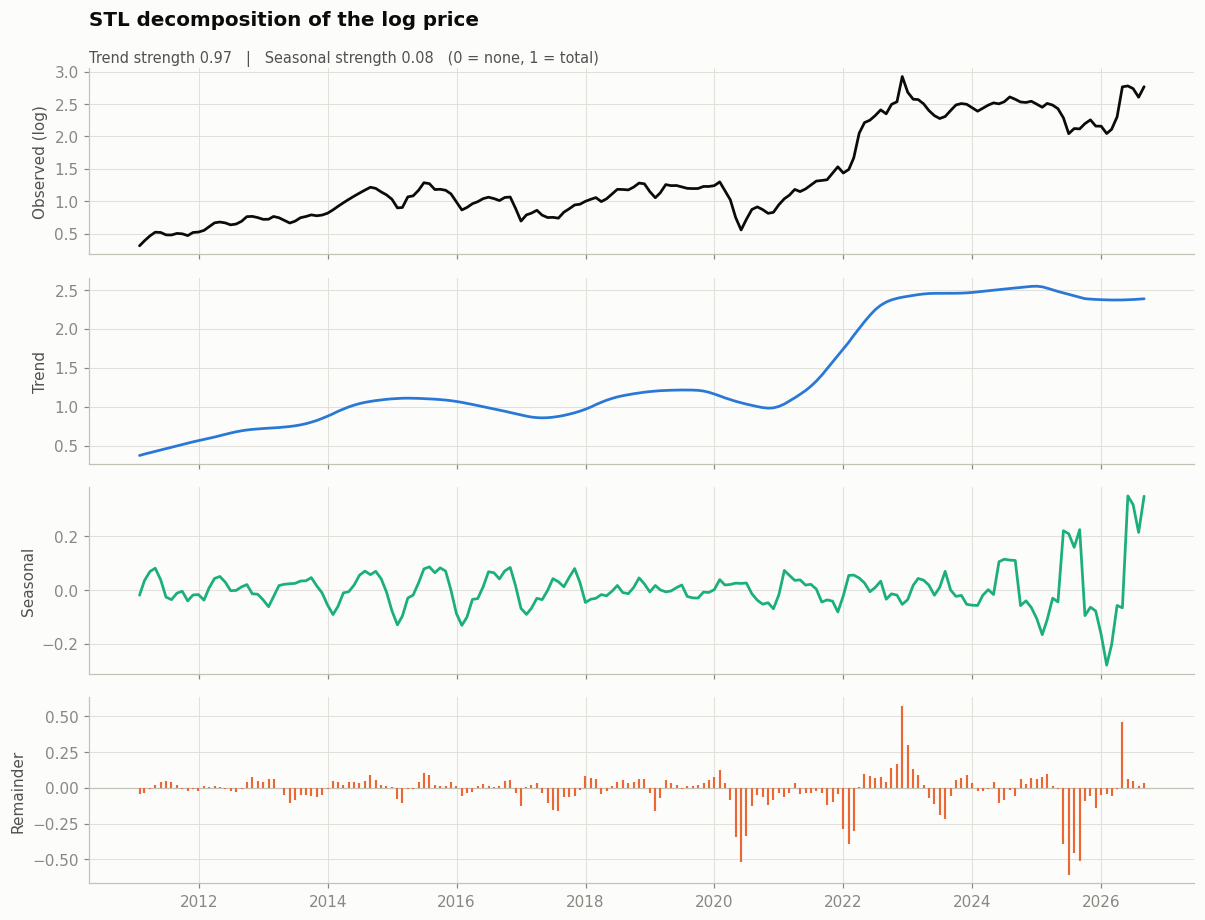

Trend strength    0.966
Seasonal strength 0.079


In [11]:
from statsmodels.tsa.seasonal import STL

stl = STL(np.log(y), period=SEASON, robust=True).fit()
parts = [("Observed (log)", np.log(y), viz.INK["primary"]),
         ("Trend", stl.trend, viz.CATEGORICAL[0]),
         ("Seasonal", stl.seasonal, viz.CATEGORICAL[2]),
         ("Remainder", stl.resid, viz.CATEGORICAL[1])]

fig, axes = plt.subplots(4, 1, figsize=(11, 8.5), sharex=True)
for ax, (name, series, color) in zip(axes, parts):
    if name == "Remainder":
        ax.axhline(0, color=viz.INK["axis"], linewidth=0.8)
        ax.vlines(series.index, 0, series.values, color=color, linewidth=1.4)
    else:
        ax.plot(series.index, series.values, color=color, linewidth=1.8)
    ax.set_ylabel(name, fontsize=10)
seas_strength = max(0.0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
trend_strength = max(0.0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
viz.titled(axes[0], "STL decomposition of the log price",
           "Trend strength %.2f   |   Seasonal strength %.2f   (0 = none, 1 = total)"
           % (trend_strength, seas_strength))
axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
viz.save_fig(fig, "05_stl_decomposition", FIG_DIR)
plt.show()

print("Trend strength    %.3f" % trend_strength)
print("Seasonal strength %.3f" % seas_strength)

### 4.2 Stationarity

ADF tests the null "there is a unit root"; KPSS tests the opposite null
"the series is stationary". Reading them together is what settles the
differencing order `d` for SARIMA, and confirms that the machine-learning
models should be given returns rather than levels.

In [12]:
from statsmodels.tsa.stattools import adfuller, kpss

def stationarity_table(series_map):
    rows = []
    for name, s in series_map.items():
        s = s.dropna()
        adf = adfuller(s, autolag="AIC")
        kp = kpss(s, regression="c", nlags="auto")
        rows.append({
            "series": name, "n": len(s),
            "ADF stat": adf[0], "ADF p": adf[1],
            "ADF verdict": "stationary" if adf[1] < 0.05 else "unit root",
            "KPSS stat": kp[0], "KPSS p": kp[1],
            "KPSS verdict": "stationary" if kp[1] > 0.05 else "non-stationary",
        })
    return pd.DataFrame(rows).set_index("series")

stat_tbl = stationarity_table({
    "Price level": y,
    "Log price": np.log(y),
    "Log return (1st difference)": np.log(y).diff(),
    "Seasonal difference of log": np.log(y).diff(SEASON),
})
stat_tbl.to_csv(TBL_DIR / "stationarity_tests.csv")
stat_tbl

/tmp/ipykernel_16867/4029349067.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kp = kpss(s, regression="c", nlags="auto")
/tmp/ipykernel_16867/4029349067.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kp = kpss(s, regression="c", nlags="auto")
/tmp/ipykernel_16867/4029349067.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kp = kpss(s, regression="c", nlags="auto")
/tmp/ipykernel_16867/4029349067.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kp = kpss(s, regression="c", nlags="auto")


,n,ADF stat,ADF p,ADF verdict,KPSS stat,KPSS p,KPSS verdict
series,,,,,,,
Price level,188,-0.3066,0.9246,unit root,1.4658,0.0100,non-stationary
Log price,188,-0.4296,0.9050,unit root,1.5927,0.0100,non-stationary
Log return (1st difference),187,-6.3863,0.0000,stationary,0.0766,0.1000,stationary
Seasonal difference of log,176,-2.5450,0.1049,unit root,0.0986,0.1000,stationary


### 4.3 Autocorrelation structure

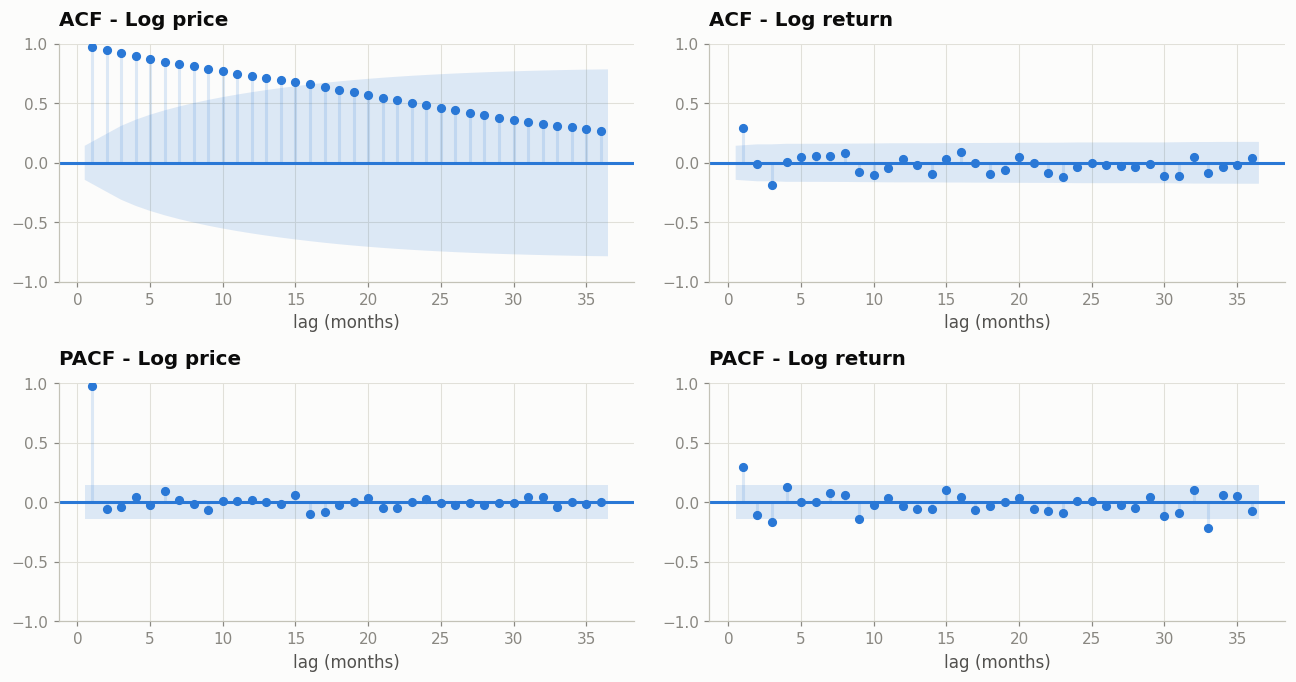

In [13]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 2, figsize=(12, 6.5))
for j, (name, series) in enumerate([("Log price", np.log(y)),
                                    ("Log return", np.log(y).diff().dropna())]):
    plot_acf(series, lags=36, ax=axes[0, j], color=viz.CATEGORICAL[0],
             vlines_kwargs={"colors": viz.CATEGORICAL[0]}, zero=False)
    plot_pacf(series, lags=36, ax=axes[1, j], method="ywm", color=viz.CATEGORICAL[0],
              vlines_kwargs={"colors": viz.CATEGORICAL[0]}, zero=False)
    axes[0, j].set_title("ACF - %s" % name, loc="left")
    axes[1, j].set_title("PACF - %s" % name, loc="left")
for ax in axes.ravel():
    for coll in ax.collections:
        coll.set_facecolor(viz.CATEGORICAL[0])
        coll.set_alpha(0.15)
    ax.set_xlabel("lag (months)")
fig.suptitle("")
fig.tight_layout()
viz.save_fig(fig, "06_acf_pacf", FIG_DIR)
plt.show()

### 4.4 Volatility and the distribution of returns

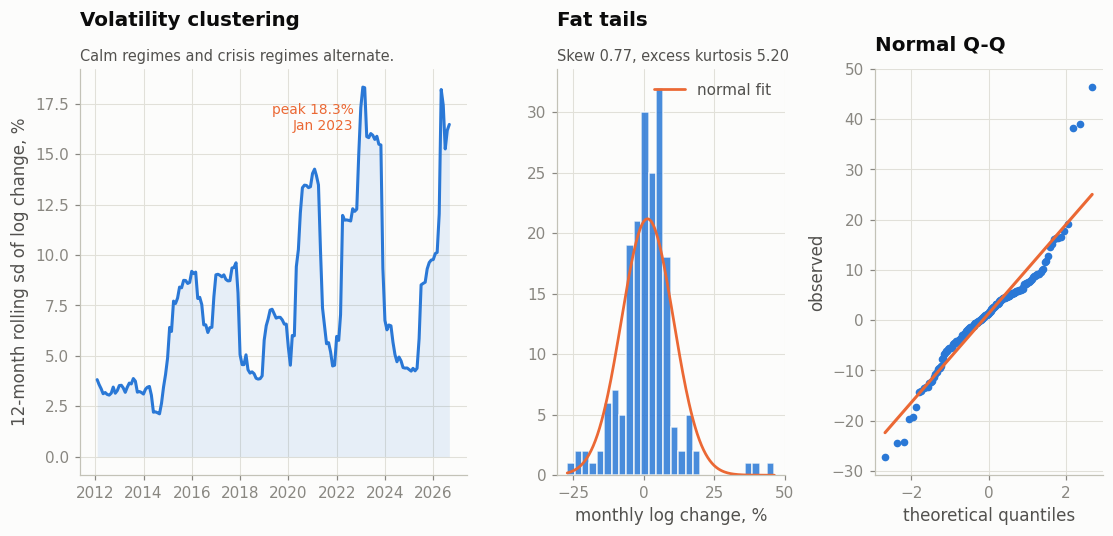

Jarque-Bera: stat 228.81, p 2.063e-50 -> returns are not normal


In [14]:
from scipy import stats as sps

fig = plt.figure(figsize=(12, 4.8))
gs = GridSpec(1, 3, figure=fig, width_ratios=[1.7, 1, 1], wspace=0.32)

ax = fig.add_subplot(gs[0, 0])
rv = r.rolling(12).std()
ax.plot(rv.index, rv.values, color=viz.CATEGORICAL[0])
ax.fill_between(rv.index, 0, rv.values, color=viz.CATEGORICAL[0], alpha=0.10, linewidth=0)
hi = rv.idxmax()
ax.annotate("peak %.1f%%\n%s" % (rv.max(), hi.strftime("%b %Y")), xy=(hi, rv.max()),
            xytext=(-6, -28), textcoords="offset points", fontsize=9,
            color=viz.CATEGORICAL[1], ha="right")
ax.set_ylabel("12-month rolling sd of log change, %")
viz.titled(ax, "Volatility clustering", "Calm regimes and crisis regimes alternate.")

ax = fig.add_subplot(gs[0, 1])
rr = r.dropna()
ax.hist(rr, bins=28, color=viz.CATEGORICAL[0], alpha=0.85, edgecolor=viz.INK["surface"])
xs = np.linspace(rr.min(), rr.max(), 200)
ax.plot(xs, sps.norm.pdf(xs, rr.mean(), rr.std()) * len(rr) * (rr.max() - rr.min()) / 28,
        color=viz.CATEGORICAL[1], linewidth=1.8, label="normal fit")
ax.set_xlabel("monthly log change, %")
ax.legend()
viz.titled(ax, "Fat tails", "Skew %.2f, excess kurtosis %.2f" % (sps.skew(rr), sps.kurtosis(rr)))

ax = fig.add_subplot(gs[0, 2])
sps.probplot(rr, dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(viz.CATEGORICAL[0])
ax.get_lines()[0].set_markeredgecolor(viz.CATEGORICAL[0])
ax.get_lines()[0].set_markersize(4)
ax.get_lines()[1].set_color(viz.CATEGORICAL[1])
ax.set_title("Normal Q-Q", loc="left")
ax.set_xlabel("theoretical quantiles"); ax.set_ylabel("observed")
fig.tight_layout()
viz.save_fig(fig, "07_volatility_distribution", FIG_DIR)
plt.show()

jb = sps.jarque_bera(rr)
print("Jarque-Bera: stat %.2f, p %.4g -> %s"
      % (jb[0], jb[1], "returns are not normal" if jb[1] < 0.05 else "normality not rejected"))

### 4.5 Seasonality by calendar month

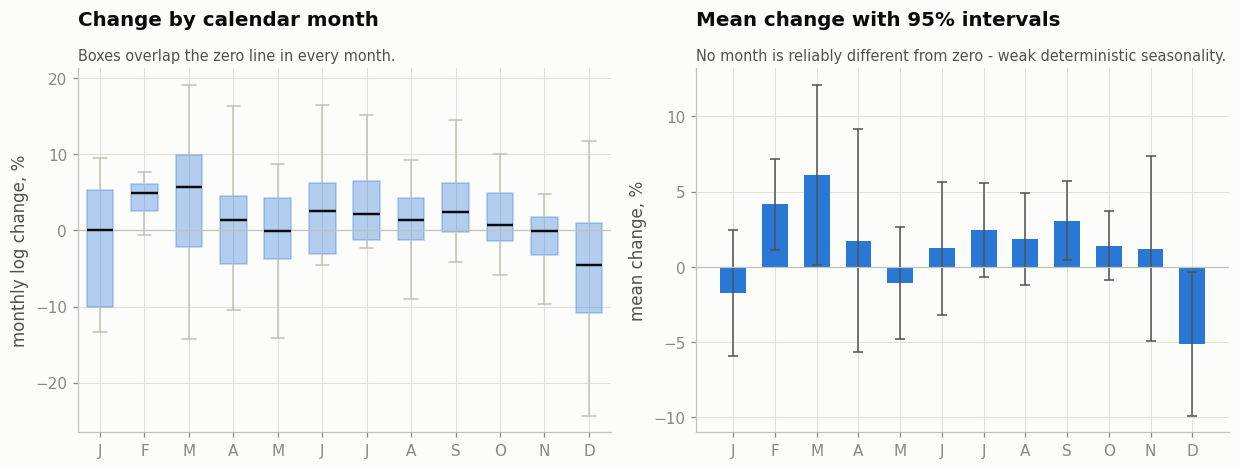

In [15]:
by_month = pd.DataFrame({"month": r.index.month, "chg": r.values}).dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

ax = axes[0]
groups = [by_month.loc[by_month["month"] == m, "chg"].values for m in range(1, 13)]
bp = ax.boxplot(groups, patch_artist=True, widths=0.6, showfliers=False,
                medianprops={"color": viz.INK["primary"], "linewidth": 1.6},
                whiskerprops={"color": viz.INK["axis"]}, capprops={"color": viz.INK["axis"]})
for patch in bp["boxes"]:
    patch.set_facecolor(viz.CATEGORICAL[0])
    patch.set_alpha(0.35)
    patch.set_edgecolor(viz.CATEGORICAL[0])
ax.axhline(0, color=viz.INK["axis"], linewidth=0.8)
ax.set_xticklabels(["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_ylabel("monthly log change, %")
viz.titled(ax, "Change by calendar month", "Boxes overlap the zero line in every month.")

ax = axes[1]
mean_by_month = by_month.groupby("month")["chg"].mean()
se = by_month.groupby("month")["chg"].sem()
ax.bar(mean_by_month.index, mean_by_month.values, color=viz.CATEGORICAL[0], width=0.62)
ax.errorbar(mean_by_month.index, mean_by_month.values, yerr=1.96 * se, fmt="none",
            ecolor=viz.INK["secondary"], elinewidth=1.0, capsize=3)
ax.axhline(0, color=viz.INK["axis"], linewidth=0.8)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_ylabel("mean change, %")
viz.titled(ax, "Mean change with 95% intervals",
           "No month is reliably different from zero - weak deterministic seasonality.")
fig.tight_layout()
viz.save_fig(fig, "08_seasonality", FIG_DIR)
plt.show()

### 4.6 What moves with what

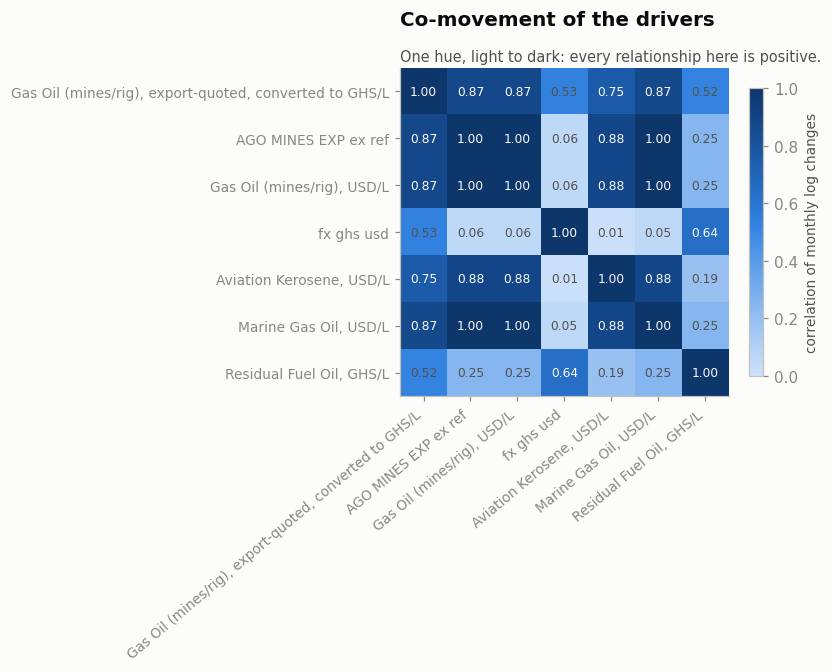

In [16]:
cm = np.log(data.where(data > 0)).diff().corr()
nice = [SERIES_LABELS.get(c, c.replace("_", " ")) for c in cm.columns]

# A diverging ramp is for data with two signs. These correlations are almost all
# positive, so a diverging map would render the whole matrix in one pole and
# waste half its range; fall back to the single-hue magnitude ramp in that case.
off_diag = cm.values[~np.eye(len(cm), dtype=bool)]
has_negative = np.nanmin(off_diag) < -0.1
cmap, vmin, vmax = ((viz.DIVERGING, -1, 1) if has_negative
                    else (viz.SEQ_BLUE, 0, 1))

fig, ax = plt.subplots(figsize=(7.6, 6.4))
im = ax.imshow(cm.values, cmap=cmap, vmin=vmin, vmax=vmax)
ax.set_xticks(range(len(nice))); ax.set_xticklabels(nice, rotation=40, ha="right", fontsize=9)
ax.set_yticks(range(len(nice))); ax.set_yticklabels(nice, fontsize=9)
for i in range(len(nice)):
    for j in range(len(nice)):
        v = cm.values[i, j]
        dark = abs(v) > 0.6 if has_negative else v > 0.62
        ax.text(j, i, "%.2f" % v, ha="center", va="center", fontsize=8,
                color=viz.INK["surface"] if dark else viz.INK["secondary"])
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.78)
cb.set_label("correlation of monthly log changes", fontsize=9)
viz.titled(ax, "Co-movement of the drivers",
           "Diverging scale, grey at zero." if has_negative
           else "One hue, light to dark: every relationship here is positive.")
fig.tight_layout()
viz.save_fig(fig, "09_correlation_matrix", FIG_DIR)
plt.show()

### 4.7 Near-duplicate drivers

The NPA publishes several export products off a shared ex-refinery
quotation, so two columns with different names can be the same series plus a
constant duty. That is not leakage - both are lagged - but it inflates the
apparent number of independent drivers and splits importance between twins,
so the duplicates are found and reported rather than left to surprise a reader.

In [17]:
dup_rows = []
cols_c = list(cm.columns)
for i in range(len(cols_c)):
    for j in range(i + 1, len(cols_c)):
        rho = cm.iloc[i, j]
        if pd.notna(rho) and abs(rho) > 0.99:
            a, b = data[cols_c[i]], data[cols_c[j]]
            dup_rows.append({
                "series A": cols_c[i], "series B": cols_c[j],
                "corr of changes": rho,
                "max abs difference": float((a - b).abs().max()),
                "mean abs difference": float((a - b).abs().mean()),
            })
duplicates = pd.DataFrame(dup_rows)
if len(duplicates):
    print("Near-duplicate driver pairs (|r| > 0.99 on monthly log changes):\n")
    print(duplicates.round(4).to_string(index=False))
    print("\nA constant gap with a correlation of 1.00 means the two columns are the")
    print("same quotation separated by a fixed excise duty. Both are retained below -")
    print("the tree models split importance between them, which is flagged in 8.1.")
else:
    print("No driver pair exceeds |r| = 0.99; the feature set carries no exact twins.")

Near-duplicate driver pairs (|r| > 0.99 on monthly log changes):

            series A            series B  corr of changes  max abs difference  mean abs difference
AGO_MINES_EXP_ex_ref AGO_MINES_EXP_price           1.0000              0.0000               0.0000
AGO_MINES_EXP_ex_ref   MGO_FOREIGN_price           0.9964              0.0666               0.0111
 AGO_MINES_EXP_price   MGO_FOREIGN_price           0.9964              0.0666               0.0111

A constant gap with a correlation of 1.00 means the two columns are the
same quotation separated by a fixed excise duty. Both are retained below -
the tree models split importance between them, which is flagged in 8.1.


## 5. Feature engineering

Every feature is dated `t-1` or earlier. That is the rule that makes the
comparison fair: the tree models and the LSTM get exactly the information a
one-step-ahead SARIMA forecast conditions on, and nothing more. The target the
learners are given is the **log return**, not the level - a tree cannot
predict a value outside the range of its training targets, so handing it a
series that has tripled since the training window would guarantee failure for
a reason that has nothing to do with the model. Levels are rebuilt afterwards
from the last observed price.

In [18]:
spec = fc.FeatureSpec(
    target=PRIMARY_TARGET,
    exog=[c for c in data.columns if c != PRIMARY_TARGET],
    lags=(1, 2, 3, 6, 12),
    roll_windows=(3, 6, 12),
    exog_lags=(1, 2, 3),
    add_calendar=True,
    add_fourier=2,
)

feats_all = fc.make_features(data, spec)
feats = feats_all.dropna()
FEATURES = fc.feature_columns(feats)

print("rows after warm-up trim : %d  (%s -> %s)"
      % (len(feats), feats.index[0].date(), feats.index[-1].date()))
print("features                : %d" % len(FEATURES))
print()
groups = {
    "autoregressive (returns)": [c for c in FEATURES if c.startswith("r_")],
    "level context": [c for c in FEATURES if c.startswith(("lvl_", "log_y"))],
    "exchange rate": [c for c in FEATURES if c.startswith("fx_")],
    "world product prices": [c for c in FEATURES
                             if c.startswith(("ATK", "MGO", "AGO", "RFO", "PREMIX"))],
    "calendar / Fourier": [c for c in FEATURES if c in ("month", "time_idx")
                           or c.startswith(("sin", "cos"))],
}
pd.DataFrame({"n features": {k: len(v) for k, v in groups.items()},
              "example": {k: (v[0] if v else "-") for k, v in groups.items()}})

rows after warm-up trim : 175  (2012-02-29 -> 2026-08-31)
features                : 72



,n features,example
autoregressive (returns),13,r_lag1
level context,5,lvl_ratio_ma3
exchange rate,8,fx_ghs_usd_lag1
world product prices,40,AGO_MINES_EXP_ex_ref_lag1
calendar / Fourier,6,month


## 6. Evaluation protocol

| | |
|---|---|
| **Split** | chronological; the final 24 months are the hold-out and are never trained on |
| **Headline horizon** | one step ahead - the model is fitted on the training span and the hold-out is filtered through it without refitting |
| **Secondary** | rolling-origin recursive forecasts at horizons 1-12, re-fitted at each origin |
| **Benchmarks** | random walk (`y_t = y_{t-1}`) and seasonal naive (`y_t = y_{t-12}`) |
| **Metrics** | RMSE, MAE, MAPE, sMAPE, MASE, R2, Theil's U2, bias, directional accuracy |
| **Significance** | Diebold-Mariano with the Harvey-Leybourne-Newbold small-sample correction |

Theil's U2 compares forecast RMSE against the random walk. MASE is scaled by
the in-sample seasonal-naive MAE (12-month lag) in forecasting.py; it is not
a direct random-walk comparison. Keep these interpretations distinct. For a
trending price series, R2 alone says little about practical forecast skill.

train : 151 months  2012-02-29 -> 2024-08-31
test  : 24 months  2024-09-30 -> 2026-08-31


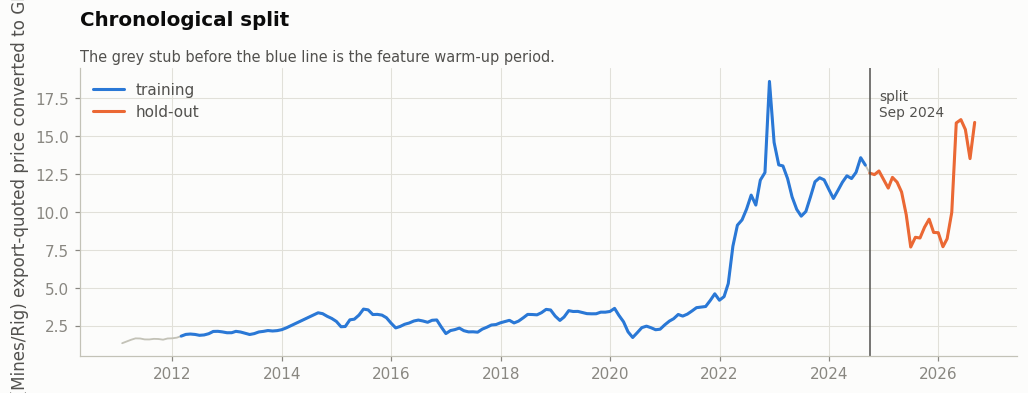

In [19]:
test_start = feats.index[-TEST_MONTHS]
is_train = feats.index < test_start
is_test = feats.index >= test_start

X_train, X_test = feats.loc[is_train, FEATURES], feats.loc[is_test, FEATURES]
r_train, r_test = feats.loc[is_train, "r"], feats.loc[is_test, "r"]
y_train, y_test = feats.loc[is_train, "y"], feats.loc[is_test, "y"]
y_prev_test = feats.loc[is_test, "y_lag1"]
test_index = feats.index[is_test]

print("train : %d months  %s -> %s" % (is_train.sum(), feats.index[0].date(),
                                       feats.index[is_train][-1].date()))
print("test  : %d months  %s -> %s" % (is_test.sum(), test_index[0].date(),
                                       test_index[-1].date()))

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(y.index, y.values, color=viz.INK["axis"], linewidth=1.2)
ax.plot(y_train.index, y_train.values, color=viz.CATEGORICAL[0], linewidth=2.0, label="training")
ax.plot(y_test.index, y_test.values, color=viz.CATEGORICAL[1], linewidth=2.0, label="hold-out")
ax.axvline(test_start, color=viz.INK["secondary"], linewidth=1.0)
ax.annotate("split\n%s" % test_start.strftime("%b %Y"), xy=(test_start, ax.get_ylim()[1]),
            xytext=(6, -14), textcoords="offset points", fontsize=9, va="top",
            color=viz.INK["secondary"])
ax.set_ylabel(TARGET_LABEL)
ax.legend(loc="upper left")
viz.titled(ax, "Chronological split", "The grey stub before the blue line is the feature warm-up period.")
viz.save_fig(fig, "10_train_test_split", FIG_DIR)
plt.show()

In [20]:
predictions = {}       # one-step-ahead level forecasts over the hold-out
fit_seconds = {}

predictions["Naive"] = y_prev_test.copy()
predictions["Seasonal Naive"] = fc.seasonal_naive_forecast(y, test_index, SEASON)

fc.assemble_results({k: predictions[k] for k in ("Naive", "Seasonal Naive")},
                    y_test, y_train, SEASON).round(4)

,RMSE,MAE,MAPE (%),sMAPE (%),R2,Theil U,Bias,MASE,Dir. Acc (%)
Naive,1.5737,1.0151,8.8712,9.0960,0.6578,1.0000,0.1171,0.7123,0.0000
Seasonal Naive,3.9478,3.2212,30.3360,28.7332,-1.1539,2.5137,-0.3105,2.2603,50.0000


## 7. Model 1 - SARIMA

The classical baseline. The grid below searches
`SARIMA(p,d,q)(P,D,Q)[12]` on the **log** price and ranks by AICc, the
small-sample corrected information criterion - with fewer than 200
observations plain AIC over-fits the order.

In [21]:
log_y = np.log(y)
t0 = time.time()
sarima_grid = fc.sarimax_grid_search(
    log_y[log_y.index < test_start],
    p_range=(0, 1, 2, 3), d_range=(1,), q_range=(0, 1, 2, 3),
    P_range=(0, 1), D_range=(0, 1), Q_range=(0, 1), season=SEASON,
)
sarima_grid_seconds = time.time() - t0
print("searched %d specifications in %.0fs" % (len(sarima_grid), sarima_grid_seconds))
sarima_grid.head(10)[["order", "seasonal_order", "AIC", "AICc", "BIC", "has_seasonal"]]

searched 128 specifications in 57s


,order,seasonal_order,AIC,AICc,BIC,has_seasonal
0,"(1, 1, 0)","(0, 0, 0, 12)",-351.9493,-351.7993,-345.7741,False
1,"(0, 1, 1)","(0, 0, 0, 12)",-349.2574,-349.1074,-343.0946,False
2,"(2, 1, 0)","(0, 0, 0, 12)",-348.8296,-348.5780,-339.5854,False
3,"(1, 1, 1)","(0, 0, 0, 12)",-348.1638,-347.9122,-338.9196,False
4,"(2, 1, 1)","(0, 0, 0, 12)",-347.2101,-346.8304,-334.8845,False
5,"(0, 1, 2)","(0, 0, 0, 12)",-345.9979,-345.7464,-336.7724,False
6,"(2, 1, 2)","(0, 0, 0, 12)",-346.1681,-345.6330,-330.7922,False
7,"(1, 1, 2)","(0, 0, 0, 12)",-345.4848,-345.1050,-333.1841,False
8,"(3, 1, 0)","(0, 0, 0, 12)",-345.0011,-344.6213,-332.7004,False
9,"(3, 1, 1)","(0, 0, 0, 12)",-344.1548,-343.6197,-328.7789,False


In [22]:
best_overall = sarima_grid.iloc[0]
best_seasonal = sarima_grid[sarima_grid["has_seasonal"]].iloc[0]

print("Best overall  : SARIMA%s%s   AICc %.2f" %
      (best_overall["order"], best_overall["seasonal_order"], best_overall["AICc"]))
print("Best seasonal : SARIMA%s%s   AICc %.2f" %
      (best_seasonal["order"], best_seasonal["seasonal_order"], best_seasonal["AICc"]))
print()
gap = best_seasonal["AICc"] - best_overall["AICc"]
print("AICc penalty for forcing a seasonal component: %.2f" % gap)
print("-> %s" % ("the data do not support seasonal terms; the selected model is a plain ARIMA"
                 if gap > 2 else "seasonal terms are competitive and are retained"))

SARIMA_ORDER = tuple(best_overall["order"])
SARIMA_SEASONAL = tuple(best_overall["seasonal_order"])

Best overall  : SARIMA(1, 1, 0)(0, 0, 0, 12)   AICc -351.80
Best seasonal : SARIMA(0, 1, 3)(1, 0, 0, 12)   AICc -317.85

AICc penalty for forcing a seasonal component: 33.95
-> the data do not support seasonal terms; the selected model is a plain ARIMA


In [23]:
t0 = time.time()
sarima_osa, sarima_res = fc.sarimax_one_step(
    log_y, test_start, SARIMA_ORDER, SARIMA_SEASONAL)
predictions["SARIMA"] = sarima_osa.reindex(test_index)
sarima_ms, sarima_ci, _ = fc.sarimax_multi_step(
    log_y, test_start, SARIMA_ORDER, SARIMA_SEASONAL, alpha=0.20)
# Order selection is part of the cost of using SARIMA, so the grid search time
# counts towards it -- otherwise the comparison charges the tree models for
# their hyper-parameter search and gives SARIMA its search for free.
fit_seconds["SARIMA"] = (time.time() - t0) + sarima_grid_seconds

print(sarima_res.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3303      0.038      8.728      0.000       0.256       0.404
sigma2         0.0065      0.000     17.336      0.000       0.006       0.007


### 7.1 Residual diagnostics

A well-specified SARIMA leaves residuals that are indistinguishable from white
noise. The Ljung-Box test is the formal check; the four panels are the visual one.

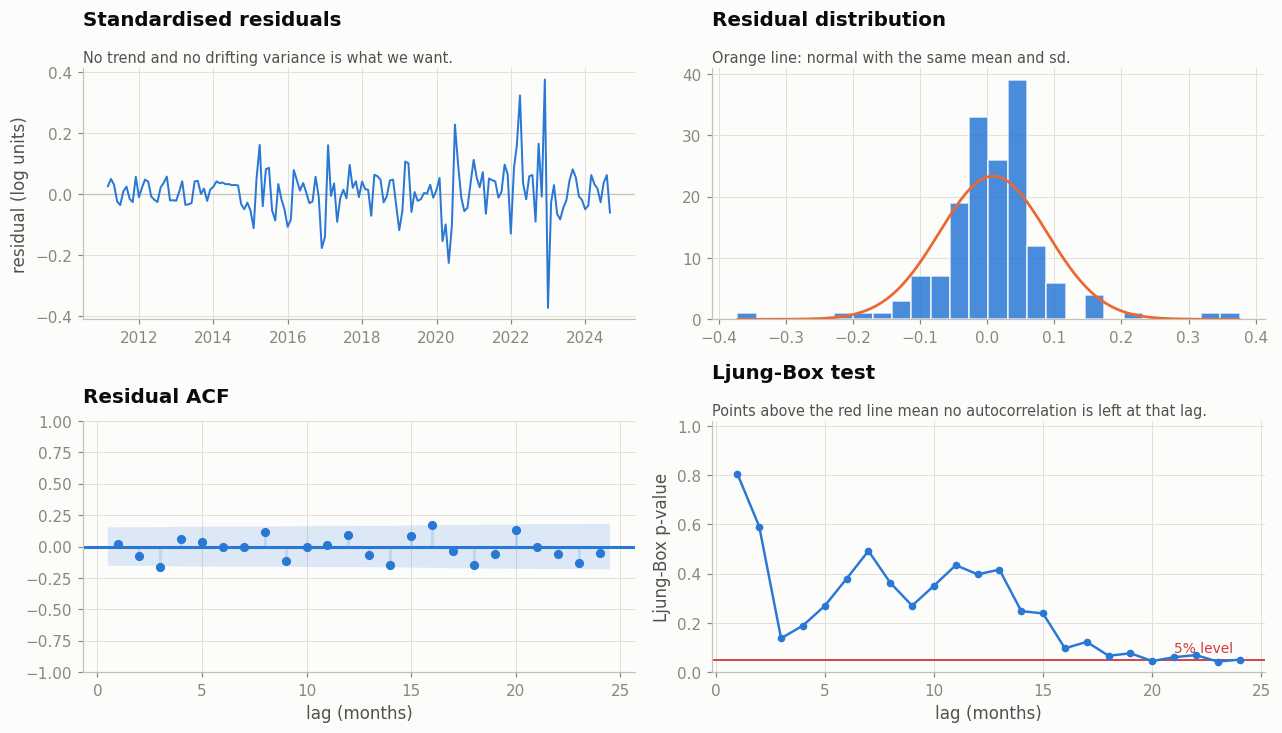

Ljung-Box rejections at the 5% level: 2 of 24 lags
Jarque-Bera on residuals: p = 1.293e-58


In [24]:
from statsmodels.stats.diagnostic import acorr_ljungbox

resid = pd.Series(sarima_res.resid, index=log_y[log_y.index < test_start].index)
resid = resid.iloc[max(SARIMA_ORDER[1], 1):]

fig, axes = plt.subplots(2, 2, figsize=(12, 6.8))
ax = axes[0, 0]
ax.axhline(0, color=viz.INK["axis"], linewidth=0.8)
ax.plot(resid.index, resid.values, color=viz.CATEGORICAL[0], linewidth=1.3)
ax.set_ylabel("residual (log units)")
viz.titled(ax, "Standardised residuals", "No trend and no drifting variance is what we want.")

ax = axes[0, 1]
ax.hist(resid, bins=26, color=viz.CATEGORICAL[0], alpha=0.85, edgecolor=viz.INK["surface"])
xs = np.linspace(resid.min(), resid.max(), 200)
ax.plot(xs, sps.norm.pdf(xs, resid.mean(), resid.std()) * len(resid) *
        (resid.max() - resid.min()) / 26, color=viz.CATEGORICAL[1], linewidth=1.8)
viz.titled(ax, "Residual distribution", "Orange line: normal with the same mean and sd.")

ax = axes[1, 0]
plot_acf(resid, lags=24, ax=ax, zero=False, color=viz.CATEGORICAL[0],
         vlines_kwargs={"colors": viz.CATEGORICAL[0]})
for coll in ax.collections:
    coll.set_facecolor(viz.CATEGORICAL[0]); coll.set_alpha(0.15)
ax.set_title("Residual ACF", loc="left"); ax.set_xlabel("lag (months)")

ax = axes[1, 1]
lb = acorr_ljungbox(resid, lags=range(1, 25), return_df=True)
ax.axhline(0.05, color=viz.STATUS["critical"], linewidth=1.2)
ax.annotate("5% level", xy=(24, 0.05), xytext=(-4, 5), textcoords="offset points",
            ha="right", fontsize=9, color=viz.STATUS["critical"])
ax.plot(lb.index, lb["lb_pvalue"].values, marker="o", color=viz.CATEGORICAL[0],
        markersize=4, linewidth=1.6)
ax.set_ylim(0, 1.02); ax.set_xlabel("lag (months)"); ax.set_ylabel("Ljung-Box p-value")
viz.titled(ax, "Ljung-Box test",
           "Points above the red line mean no autocorrelation is left at that lag.")
fig.tight_layout()
viz.save_fig(fig, "11_sarima_diagnostics", FIG_DIR)
plt.show()

n_reject = int((lb["lb_pvalue"] < 0.05).sum())
print("Ljung-Box rejections at the 5%% level: %d of %d lags" % (n_reject, len(lb)))
print("Jarque-Bera on residuals: p = %.4g" % sps.jarque_bera(resid)[1])

## 8. Model 2 - Random Forest

Tuned by randomised search over a `TimeSeriesSplit`, so every validation fold
is strictly later than the data used to fit it. Scoring on MAE of the log
return rather than MSE keeps the search from being dominated by the two or
three crisis months.

In [25]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.inspection import permutation_importance

cv = TimeSeriesSplit(n_splits=5)

# The search parallelises across candidates; the estimator inside it stays
# single-threaded. Two nested `n_jobs=-1` layers oversubscribe every core and
# make the search several times slower than running it serially.
INNER_JOBS, SEARCH_JOBS = 1, -1

rf_space = {
    "n_estimators": [300, 600, 1000],
    "max_depth": [3, 5, 8, 12, None],
    "min_samples_leaf": [1, 2, 4, 8],
    "min_samples_split": [2, 5, 10],
    "max_features": [0.2, 0.35, 0.5, 0.8, "sqrt"],
}

t0 = time.time()
rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=INNER_JOBS, bootstrap=True),
    rf_space, n_iter=40, cv=cv, scoring="neg_mean_absolute_error",
    random_state=RANDOM_STATE, n_jobs=SEARCH_JOBS, refit=True,
).fit(X_train, r_train)
fit_seconds["Random Forest"] = time.time() - t0

rf = rf_search.best_estimator_.set_params(n_jobs=-1)
predictions["Random Forest"] = y_prev_test * np.exp(rf.predict(X_test))

print("best CV MAE (log return): %.5f" % (-rf_search.best_score_))
print("fitted in %.1fs" % fit_seconds["Random Forest"])
pd.Series(rf_search.best_params_).to_frame("value")

best CV MAE (log return): 0.06848
fitted in 95.1s


,value
n_estimators,300.0000
min_samples_split,2.0000
min_samples_leaf,8.0000
max_features,0.8000
max_depth,12.0000


### 8.1 What the forest actually uses

Impurity importance is biased towards high-cardinality features, so
permutation importance on the hold-out is reported alongside it: the honest
question is how much accuracy is lost when a feature is shuffled.

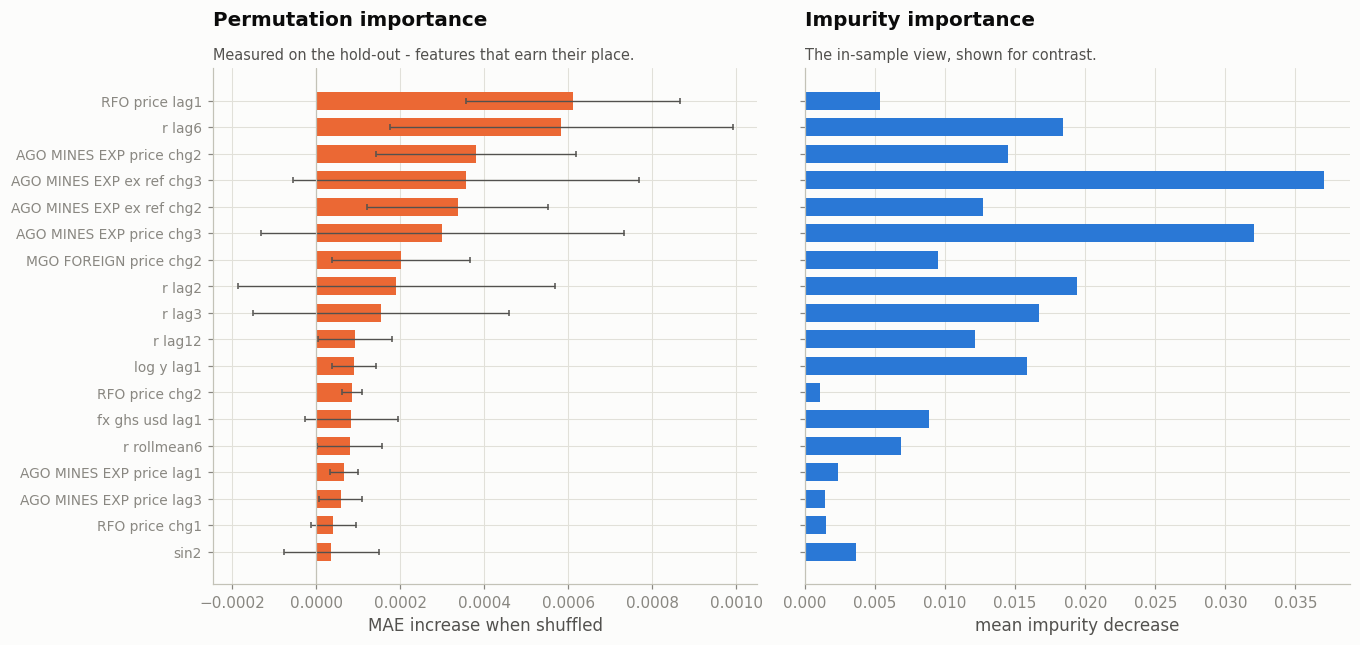

,impurity,permutation,perm_sd
feature,,,
RFO_price_lag1,0.0053,0.0006,0.0003
r_lag6,0.0184,0.0006,0.0004
AGO_MINES_EXP_price_chg2,0.0145,0.0004,0.0002
AGO_MINES_EXP_ex_ref_chg3,0.0370,0.0004,0.0004
AGO_MINES_EXP_ex_ref_chg2,0.0127,0.0003,0.0002
AGO_MINES_EXP_price_chg3,0.0321,0.0003,0.0004
MGO_FOREIGN_price_chg2,0.0095,0.0002,0.0002
r_lag2,0.0194,0.0002,0.0004
r_lag3,0.0167,0.0001,0.0003


In [26]:
perm = permutation_importance(rf, X_test, r_test, n_repeats=30,
                              random_state=RANDOM_STATE, scoring="neg_mean_absolute_error")
imp = pd.DataFrame({
    "feature": FEATURES,
    "impurity": rf.feature_importances_,
    "permutation": perm.importances_mean,
    "perm_sd": perm.importances_std,
}).sort_values("permutation", ascending=False)
imp.to_csv(TBL_DIR / "rf_feature_importance.csv", index=False)

top = imp.head(18).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 6), sharey=True)
ax = axes[0]
ax.barh(range(len(top)), top["permutation"], color=viz.CATEGORICAL[1], height=0.68)
ax.errorbar(top["permutation"], range(len(top)), xerr=top["perm_sd"], fmt="none",
            ecolor=viz.INK["secondary"], elinewidth=0.9, capsize=2)
ax.set_yticks(range(len(top)))
ax.set_yticklabels([f.replace("_", " ") for f in top["feature"]], fontsize=9)
ax.axvline(0, color=viz.INK["axis"], linewidth=0.8)
ax.set_xlabel("MAE increase when shuffled")
viz.titled(ax, "Permutation importance", "Measured on the hold-out - features that earn their place.")

ax = axes[1]
ax.barh(range(len(top)), top["impurity"], color=viz.CATEGORICAL[0], height=0.68)
ax.set_xlabel("mean impurity decrease")
viz.titled(ax, "Impurity importance", "The in-sample view, shown for contrast.")
fig.tight_layout()
viz.save_fig(fig, "12_rf_importance", FIG_DIR)
plt.show()

imp.head(12).set_index("feature").round(5)

## 9. Model 3 - XGBoost

Same protocol, a wider search space, and early stopping on a held-back tail of
the training span so the number of boosting rounds is chosen rather than guessed.

In [27]:
import xgboost as xgb

xgb_space = {
    "n_estimators": [300, 600, 1000, 1500],
    "learning_rate": [0.005, 0.01, 0.03, 0.06, 0.1],
    "max_depth": [2, 3, 4, 6],
    "min_child_weight": [1, 3, 6, 10],
    "subsample": [0.6, 0.75, 0.9, 1.0],
    "colsample_bytree": [0.3, 0.5, 0.7, 0.9],
    "reg_lambda": [0.5, 1.0, 3.0, 10.0],
    "reg_alpha": [0.0, 0.1, 1.0],
    "gamma": [0.0, 0.1, 0.5],
}

t0 = time.time()
xgb_search = RandomizedSearchCV(
    xgb.XGBRegressor(random_state=RANDOM_STATE, n_jobs=INNER_JOBS, tree_method="hist",
                     objective="reg:squarederror"),
    xgb_space, n_iter=60, cv=cv, scoring="neg_mean_absolute_error",
    random_state=RANDOM_STATE, n_jobs=SEARCH_JOBS, refit=True,
).fit(X_train, r_train)
fit_seconds["XGBoost"] = time.time() - t0

xgbm = xgb_search.best_estimator_.set_params(n_jobs=-1)
predictions["XGBoost"] = y_prev_test * np.exp(xgbm.predict(X_test))

print("best CV MAE (log return): %.5f" % (-xgb_search.best_score_))
print("fitted in %.1fs" % fit_seconds["XGBoost"])
pd.Series(xgb_search.best_params_).to_frame("value")

best CV MAE (log return): 0.06795
fitted in 49.0s


,value
subsample,0.6000
reg_lambda,3.0000
reg_alpha,0.0000
n_estimators,600.0000
min_child_weight,3.0000
max_depth,6.0000
learning_rate,0.0300
gamma,0.1000
colsample_bytree,0.7000


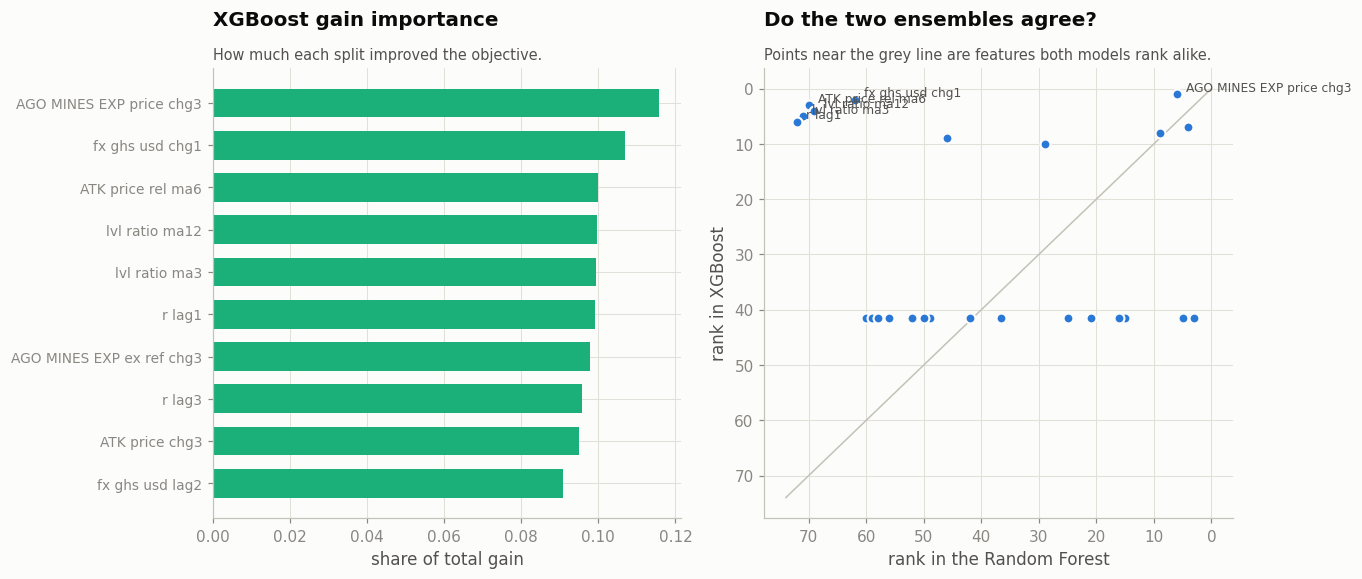

Spearman rank correlation between the two importance orderings: -0.151


In [28]:
gain = xgbm.get_booster().get_score(importance_type="gain")
xgb_imp = (pd.Series(gain).rename("gain").to_frame()
           .assign(gain=lambda d: d["gain"] / d["gain"].sum())
           .sort_values("gain", ascending=False))
xgb_imp.to_csv(TBL_DIR / "xgb_feature_importance.csv")

both = (imp.set_index("feature")[["permutation"]]
        .join(xgb_imp, how="outer").fillna(0.0))
both["rank_rf"] = both["permutation"].rank(ascending=False)
both["rank_xgb"] = both["gain"].rank(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.4))
ax = axes[0]
topx = xgb_imp.head(16).iloc[::-1]
ax.barh(range(len(topx)), topx["gain"], color=viz.CATEGORICAL[2], height=0.68)
ax.set_yticks(range(len(topx)))
ax.set_yticklabels([f.replace("_", " ") for f in topx.index], fontsize=9)
ax.set_xlabel("share of total gain")
viz.titled(ax, "XGBoost gain importance", "How much each split improved the objective.")

ax = axes[1]
sel = both.nsmallest(25, "rank_xgb")
ax.scatter(sel["rank_rf"], sel["rank_xgb"], s=42, color=viz.CATEGORICAL[0],
           edgecolor=viz.INK["surface"], linewidth=1.4, zorder=3)
lims = [0, max(sel["rank_rf"].max(), sel["rank_xgb"].max()) + 2]
ax.plot(lims, lims, color=viz.INK["axis"], linewidth=1.0, zorder=1)
for f, row in sel.nsmallest(6, "rank_xgb").iterrows():
    ax.annotate(f.replace("_", " "), xy=(row["rank_rf"], row["rank_xgb"]),
                xytext=(6, 2), textcoords="offset points", fontsize=8,
                color=viz.INK["secondary"])
ax.set_xlabel("rank in the Random Forest"); ax.set_ylabel("rank in XGBoost")
ax.invert_xaxis(); ax.invert_yaxis()
viz.titled(ax, "Do the two ensembles agree?",
           "Points near the grey line are features both models rank alike.")
fig.tight_layout()
viz.save_fig(fig, "13_xgb_importance", FIG_DIR)
plt.show()

print("Spearman rank correlation between the two importance orderings: %.3f"
      % both[["rank_rf", "rank_xgb"]].corr(method="spearman").iloc[0, 1])

## 10. Model 4 - LSTM

A two-layer LSTM reading a rolling 12-month window of the same feature vectors
and predicting the next log return. The network is deliberately small - with
fewer than 200 training months a larger one memorises the window rather than
learning from it - and it is fitted from five random seeds whose predictions
are averaged, so the reported result is not an artefact of one lucky
initialisation. Early stopping watches a held-back tail of the training span.

In [29]:
t0 = time.time()
lstm = fc.LSTMRegressor(
    window=12, hidden=48, layers=2, dropout=0.15,
    lr=8e-3, epochs=400, patience=40, batch_size=32,
    val_frac=0.15, n_seeds=5, verbose=True,
)
lstm.fit(X_train, r_train)
predictions["LSTM"] = y_prev_test * np.exp(lstm.predict(X_test, context=X_train))
fit_seconds["LSTM"] = time.time() - t0
print("\nfitted %d seeds on %s in %.1fs" % (lstm.n_seeds, lstm.device, fit_seconds["LSTM"]))

  seed 0: best val 0.85212 after 41 epochs


  seed 1: best val 0.51631 after 41 epochs


  seed 2: best val 0.62483 after 43 epochs


  seed 3: best val 0.56970 after 42 epochs


  seed 4: best val 0.69175 after 41 epochs

fitted 5 seeds on cpu in 12.6s


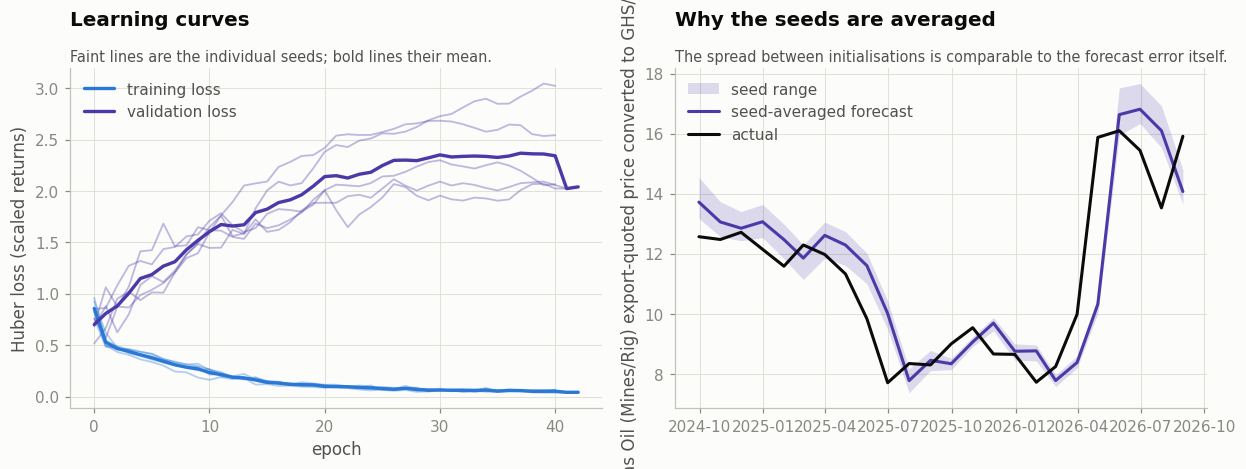

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
for i, h in enumerate(lstm.history_):
    ax.plot(h["val"], color=viz.CATEGORICAL[6], alpha=0.35, linewidth=1.2)
    ax.plot(h["train"], color=viz.CATEGORICAL[0], alpha=0.35, linewidth=1.2)
longest = max(len(h["val"]) for h in lstm.history_)
mean_val = [np.mean([h["val"][e] for h in lstm.history_ if len(h["val"]) > e])
            for e in range(longest)]
mean_tr = [np.mean([h["train"][e] for h in lstm.history_ if len(h["train"]) > e])
           for e in range(longest)]
ax.plot(mean_tr, color=viz.CATEGORICAL[0], linewidth=2.2, label="training loss")
ax.plot(mean_val, color=viz.CATEGORICAL[6], linewidth=2.2, label="validation loss")
ax.set_xlabel("epoch"); ax.set_ylabel("Huber loss (scaled returns)")
ax.legend()
viz.titled(ax, "Learning curves", "Faint lines are the individual seeds; bold lines their mean.")

ax = axes[1]
seed_preds = []
for net in lstm.models_:
    saved, lstm.models_ = lstm.models_, [net]
    seed_preds.append(y_prev_test * np.exp(lstm.predict(X_test, context=X_train)))
    lstm.models_ = saved
sp = pd.concat(seed_preds, axis=1)
ax.fill_between(test_index, sp.min(axis=1), sp.max(axis=1),
                color=viz.CATEGORICAL[6], alpha=0.18, linewidth=0, label="seed range")
ax.plot(test_index, predictions["LSTM"].values, color=viz.CATEGORICAL[6],
        linewidth=2.0, label="seed-averaged forecast")
ax.plot(test_index, y_test.values, color=viz.INK["primary"], linewidth=2.0, label="actual")
ax.set_ylabel(TARGET_LABEL)
ax.legend(loc="upper left")
viz.titled(ax, "Why the seeds are averaged",
           "The spread between initialisations is comparable to the forecast error itself.")
fig.tight_layout()
viz.save_fig(fig, "14_lstm_training", FIG_DIR)
plt.show()

## 11. Forecast combination

Combining forecasts is the most reliably useful trick in the literature: as
long as the component errors are not perfectly correlated, an equal-weight
average has lower variance than its members. It is included here as a fifth
entry rather than as a claim about any one model.

In [31]:
components = ["SARIMA", "Random Forest", "XGBoost", "LSTM"]
predictions["Ensemble"] = pd.concat([predictions[c] for c in components], axis=1).mean(axis=1)

err_corr = pd.DataFrame({c: (y_test - predictions[c]) for c in components}).corr()
print("Correlation between the component forecast errors:")
err_corr.round(3)

Correlation between the component forecast errors:


,SARIMA,Random Forest,XGBoost,LSTM
SARIMA,1.0000,0.9640,0.9560,0.9370
Random Forest,0.9640,1.0000,0.9930,0.9750
XGBoost,0.9560,0.9930,1.0000,0.9890
LSTM,0.9370,0.9750,0.9890,1.0000


## 12. Results

### 12.1 The comparison table

In [32]:
MODEL_ORDER = ["Naive", "Seasonal Naive", "SARIMA", "Random Forest", "XGBoost", "LSTM", "Ensemble"]
ordered = {k: predictions[k] for k in MODEL_ORDER if k in predictions}

results = fc.assemble_results(ordered, y_test, y_train, SEASON)
results = results[["RMSE", "MAE", "MAPE (%)", "sMAPE (%)", "MASE", "Theil U",
                   "R2", "Dir. Acc (%)", "Bias"]]
results.index.name = "Model"
results.to_csv(TBL_DIR / "headline_metrics.csv")

with open(TBL_DIR / "headline_metrics.tex", "w") as fh:
    fh.write(results.round(4).to_latex(
        caption="One-step-ahead forecast accuracy over the %d-month hold-out (%s)."
                % (TEST_MONTHS, SERIES_LABELS.get(PRIMARY_TARGET, PRIMARY_TARGET)),
        label="tab:headline", escape=True))

viz.metric_table_style(results.round(4))

,RMSE,MAE,MAPE (%),sMAPE (%),MASE,Theil U,R2,Dir. Acc (%),Bias
Model,,,,,,,,,
Naive,1.5737,1.0151,8.8712,9.0960,0.7123,1.0000,0.6578,0.0000,0.1171
Seasonal Naive,3.9478,3.2212,30.3360,28.7332,2.2603,2.5137,-1.1539,50.0000,-0.3105
SARIMA,1.5738,1.1199,9.6465,9.8729,0.7859,1.0013,0.6577,50.0000,0.0725
Random Forest,1.5144,1.1042,9.5581,9.7159,0.7748,0.9617,0.6830,41.6667,0.0362
XGBoost,1.5729,1.0970,9.5020,9.6695,0.7698,0.9987,0.6581,37.5000,0.0072
LSTM,1.6112,1.1575,10.1086,10.1028,0.8122,1.0154,0.6412,41.6667,-0.1892
Ensemble,1.5463,1.1124,9.6382,9.7790,0.7806,0.9810,0.6695,41.6667,-0.0183


In [33]:
best_rmse = results["RMSE"].idxmin()
beat_rw = results[results["Theil U"] < 1].index.tolist()

print("Lowest RMSE                     : %s (%.4f)" % (best_rmse, results.loc[best_rmse, "RMSE"]))
print("Lowest MAPE                     : %s (%.2f%%)"
      % (results["MAPE (%)"].idxmin(), results["MAPE (%)"].min()))
print("Best directional accuracy       : %s (%.1f%%)"
      % (results["Dir. Acc (%)"].idxmax(), results["Dir. Acc (%)"].max()))
print("Beat the random walk (U < 1)    : %s"
      % (", ".join(m for m in beat_rw if m != "Naive") or "none"))

Lowest RMSE                     : Random Forest (1.5144)
Lowest MAPE                     : Naive (8.87%)
Best directional accuracy       : Seasonal Naive (50.0%)
Beat the random walk (U < 1)    : Random Forest, XGBoost, Ensemble


### 12.2 Forecasts against the outturn

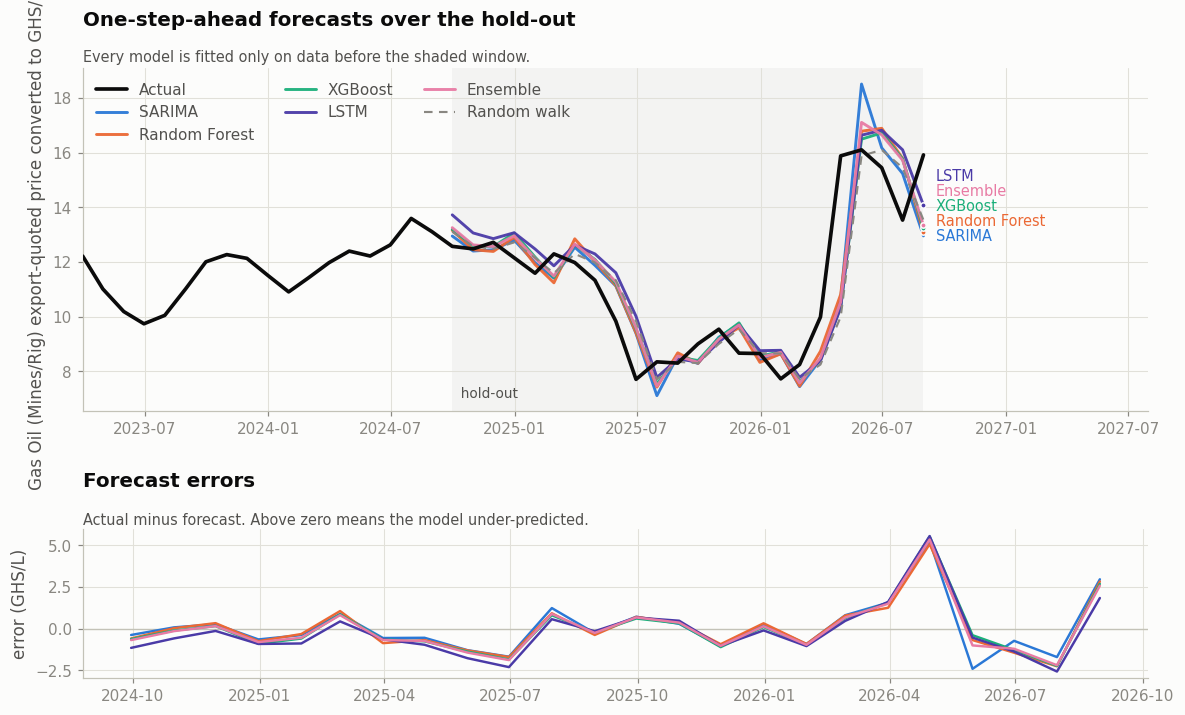

In [34]:
fig = plt.figure(figsize=(12.5, 7.2))
gs = GridSpec(2, 1, height_ratios=[2.3, 1], hspace=0.48, figure=fig)

ax = fig.add_subplot(gs[0])
context = y.loc[y.index >= test_start - pd.DateOffset(months=18)]
ax.plot(context.index, context.values, color=viz.INK["primary"], linewidth=2.4, label="Actual",
        zorder=6)
ends = []
for name in MODEL_ORDER:
    if name in ("Naive", "Seasonal Naive"):
        continue
    p = predictions[name]
    ax.plot(p.index, p.values, color=viz.MODEL_COLORS[name], linewidth=1.9,
            label=name, alpha=0.95)
    ends.append((p.index[-1], p.iloc[-1], name, viz.MODEL_COLORS[name]))
ax.plot(test_index, predictions["Naive"].values, color=viz.INK["muted"],
        linewidth=1.4, linestyle=(0, (4, 3)), label="Random walk", zorder=2)
# The label goes at the foot of the shaded span so it cannot land under the legend.
viz.shade_span(ax, test_start, test_index[-1])
ax.text(test_start, 0.03, "  hold-out", transform=ax.get_xaxis_transform(),
        color=viz.INK["secondary"], fontsize=9, va="bottom", ha="left")
ax.set_xlim(context.index[0], test_index[-1] + pd.DateOffset(months=11))
ax.set_ylabel(TARGET_LABEL)
ax.legend(loc="upper left", ncol=3)
viz.titled(ax, "One-step-ahead forecasts over the hold-out",
           "Every model is fitted only on data before the shaded window.")
# All four forecasts converge on the final month, so their endpoint labels have
# to be separated explicitly.
viz.label_ends(ax, ends, min_gap=15)

ax = fig.add_subplot(gs[1])
ax.axhline(0, color=viz.INK["axis"], linewidth=0.9)
for name in ["SARIMA", "Random Forest", "XGBoost", "LSTM", "Ensemble"]:
    e = y_test - predictions[name]
    ax.plot(e.index, e.values, color=viz.MODEL_COLORS[name], linewidth=1.6, label=name)
ax.set_ylabel("error (GHS/L)")
viz.titled(ax, "Forecast errors", "Actual minus forecast. Above zero means the model under-predicted.")
viz.save_fig(fig, "15_forecasts_vs_actual", FIG_DIR)
plt.show()

### 12.3 Error distributions

The mean error hides whether a model is steadily a little wrong or
occasionally very wrong. The spread is what a planner actually cares about.

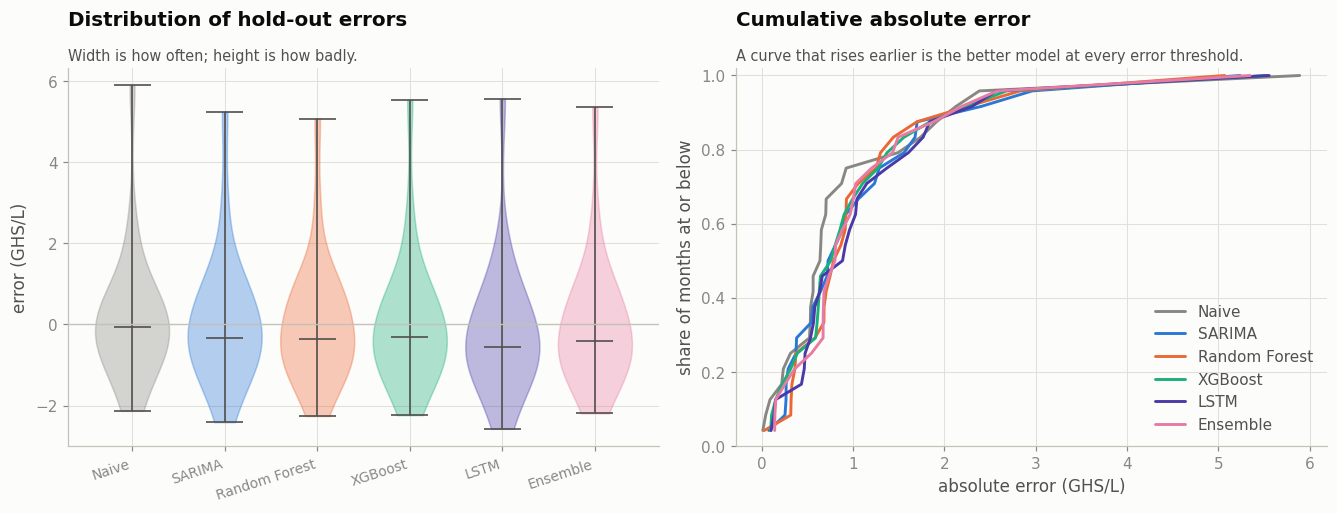

In [35]:
models_plot = ["Naive", "SARIMA", "Random Forest", "XGBoost", "LSTM", "Ensemble"]
errs = {m: (y_test - predictions[m]).dropna().values for m in models_plot}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
ax = axes[0]
parts = ax.violinplot([errs[m] for m in models_plot], showmedians=True, widths=0.8)
for i, body in enumerate(parts["bodies"]):
    body.set_facecolor(viz.MODEL_COLORS[models_plot[i]])
    body.set_alpha(0.35); body.set_edgecolor(viz.MODEL_COLORS[models_plot[i]])
for key in ("cmedians", "cbars", "cmins", "cmaxes"):
    if key in parts:
        parts[key].set_color(viz.INK["secondary"]); parts[key].set_linewidth(1.1)
ax.axhline(0, color=viz.INK["axis"], linewidth=0.9)
ax.set_xticks(range(1, len(models_plot) + 1))
ax.set_xticklabels(models_plot, rotation=18, ha="right", fontsize=9)
ax.set_ylabel("error (GHS/L)")
viz.titled(ax, "Distribution of hold-out errors", "Width is how often; height is how badly.")

ax = axes[1]
for m in models_plot:
    a = np.sort(np.abs(errs[m]))
    ax.plot(a, np.arange(1, len(a) + 1) / len(a), color=viz.MODEL_COLORS[m],
            linewidth=1.9, label=m)
ax.set_xlabel("absolute error (GHS/L)"); ax.set_ylabel("share of months at or below")
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right")
viz.titled(ax, "Cumulative absolute error",
           "A curve that rises earlier is the better model at every error threshold.")
fig.tight_layout()
viz.save_fig(fig, "16_error_distribution", FIG_DIR)
plt.show()

### 12.4 Is the difference real?

A lower RMSE over 24 months can be luck. The Diebold-Mariano test asks whether
the squared-error sequences differ by more than sampling noise, using the
Harvey-Leybourne-Newbold correction for the short sample.

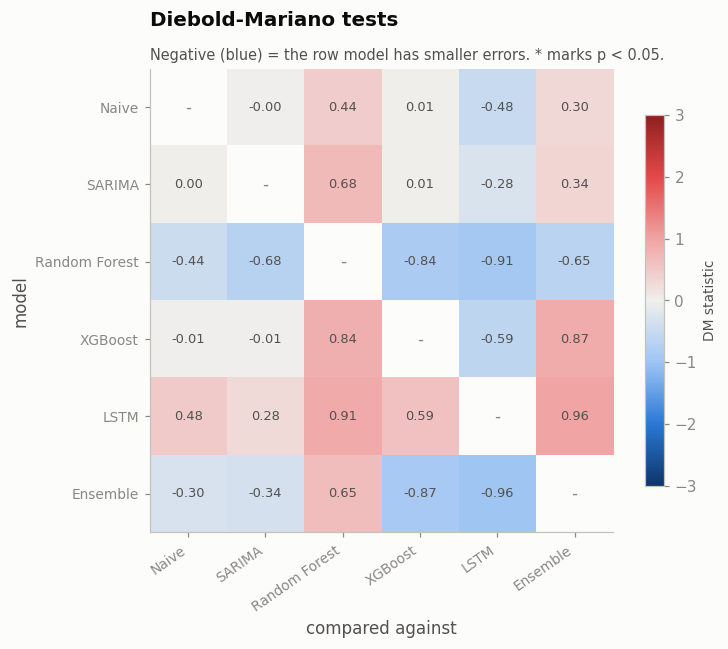

No pair differs significantly at the 5% level over 24 months.
With a hold-out this short that is the expected outcome, and it is the
reason the multi-horizon study below pools errors across many origins.


In [36]:
dm_models = ["Naive", "SARIMA", "Random Forest", "XGBoost", "LSTM", "Ensemble"]
dm_stat = pd.DataFrame(np.nan, index=dm_models, columns=dm_models)
dm_p = pd.DataFrame(np.nan, index=dm_models, columns=dm_models)
for a in dm_models:
    for b in dm_models:
        if a == b:
            continue
        s, p = fc.diebold_mariano(y_test - predictions[a], y_test - predictions[b], h=1)
        dm_stat.loc[a, b], dm_p.loc[a, b] = s, p

fig, ax = plt.subplots(figsize=(7.4, 6))
im = ax.imshow(dm_stat.values.astype(float), cmap=viz.DIVERGING, vmin=-3, vmax=3)
ax.set_xticks(range(len(dm_models))); ax.set_xticklabels(dm_models, rotation=35, ha="right", fontsize=9)
ax.set_yticks(range(len(dm_models))); ax.set_yticklabels(dm_models, fontsize=9)
for i, a in enumerate(dm_models):
    for j, b in enumerate(dm_models):
        if i == j:
            ax.text(j, i, "-", ha="center", va="center", color=viz.INK["muted"]); continue
        s, p = dm_stat.iloc[i, j], dm_p.iloc[i, j]
        star = "*" if p < 0.05 else ""
        ax.text(j, i, "%.2f%s" % (s, star), ha="center", va="center", fontsize=8.5,
                color=viz.INK["surface"] if abs(s) > 1.8 else viz.INK["secondary"])
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.set_label("DM statistic", fontsize=9)
ax.set_xlabel("compared against"); ax.set_ylabel("model")
viz.titled(ax, "Diebold-Mariano tests",
           "Negative (blue) = the row model has smaller errors. * marks p < 0.05.")
fig.tight_layout()
viz.save_fig(fig, "17_diebold_mariano", FIG_DIR)
plt.show()

dm_p.round(3).to_csv(TBL_DIR / "diebold_mariano_pvalues.csv")
sig = [(a, b, dm_stat.loc[a, b], dm_p.loc[a, b])
       for a in dm_models for b in dm_models
       if a != b and pd.notna(dm_p.loc[a, b]) and dm_p.loc[a, b] < 0.05 and dm_stat.loc[a, b] < 0]
if sig:
    print("Significantly better at the 5% level:")
    for a, b, s, p in sig:
        print("   %-14s beats %-14s  DM %.2f, p = %.3f" % (a, b, s, p))
else:
    print("No pair differs significantly at the 5%% level over %d months." % TEST_MONTHS)
    print("With a hold-out this short that is the expected outcome, and it is the")
    print("reason the multi-horizon study below pools errors across many origins.")

## 13. How accuracy decays with the horizon

One month ahead, a random walk is a formidable benchmark for any price series.
The question that matters for planning is what happens further out, where the
random walk simply freezes at the last observed price. Each origin below is
re-fitted on data available at that date and rolled forward recursively.

24 origins x 12 horizons in 68s


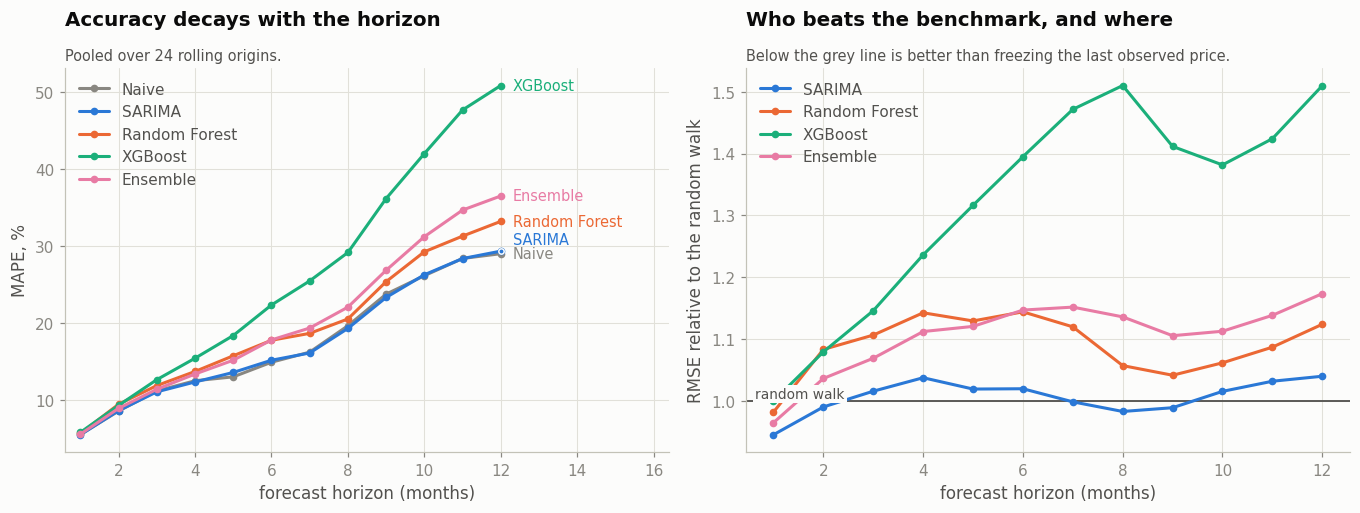

,Naive|MAPE,Naive|U,SARIMA|MAPE,SARIMA|U,Random Forest|MAPE,Random Forest|U,XGBoost|MAPE,XGBoost|U,Ensemble|MAPE,Ensemble|U
h,,,,,,,,,,
1,5.5040,1.0000,5.4660,0.9450,5.6490,0.9820,5.7790,1.0000,5.5400,0.9650
2,8.5510,1.0000,8.6100,0.9900,9.4340,1.0830,9.2900,1.0790,8.9000,1.0360
3,11.1630,1.0000,11.0460,1.0160,11.8610,1.1070,12.6310,1.1460,11.3810,1.0690
4,12.4870,1.0000,12.3290,1.0380,13.6950,1.1430,15.4160,1.2360,13.3610,1.1120
5,12.9930,1.0000,13.5660,1.0190,15.7330,1.1290,18.3670,1.3160,15.1570,1.1210
6,14.8940,1.0000,15.1530,1.0200,17.7500,1.1440,22.3370,1.3950,17.7950,1.1470
7,16.2060,1.0000,16.0950,0.9990,18.6460,1.1200,25.4640,1.4720,19.3390,1.1520
8,19.6370,1.0000,19.2920,0.9830,20.5190,1.0570,29.1610,1.5100,22.0560,1.1360
9,23.7460,1.0000,23.3140,0.9890,25.3680,1.0420,36.1720,1.4120,26.8470,1.1060


In [37]:
def multi_horizon_study(frame, spec_, hmax=MAX_HORIZON, n_origins=N_ORIGINS):
    f_all = fc.make_features(frame, spec_).dropna()
    Xa = f_all[fc.feature_columns(f_all)]
    idx = f_all.index
    origins = idx[-(n_origins + hmax):-hmax]
    logy_ = np.log(frame[spec_.target])
    rows = []
    for o in origins:
        tr_ = idx < o
        if tr_.sum() < 5 * SEASON:
            continue
        r_ = f_all.loc[tr_, "r"]
        rf_o = RandomForestRegressor(**{**rf_search.best_params_,
                                        "random_state": RANDOM_STATE, "n_jobs": -1}).fit(Xa[tr_], r_)
        xg_o = xgb.XGBRegressor(**{**xgb_search.best_params_, "random_state": RANDOM_STATE,
                                   "n_jobs": -1, "tree_method": "hist"}).fit(Xa[tr_], r_)
        fut = idx[idx >= o][:hmax]
        hist = frame.loc[frame.index < o]
        # Do not pass observed future explanatory variables into the recursive
        # forecast. The forecast function carries each exogenous series forward
        # from its last value available before this origin (a persistence
        # scenario), preventing information leakage from future NPA prices.
        p_rf = fc.recursive_forecast(
            hist, fut, spec_, lambda z, c: rf_o.predict(z),
            exog_future=None, columns=Xa.columns
        )
        p_xg = fc.recursive_forecast(
            hist, fut, spec_, lambda z, c: xg_o.predict(z),
            exog_future=None, columns=Xa.columns
        )
        try:
            p_sa, _, _ = fc.sarimax_multi_step(logy_, o, SARIMA_ORDER, SARIMA_SEASONAL)
            p_sa = p_sa.iloc[:hmax]
        except Exception:
            p_sa = pd.Series(np.nan, index=fut)
        last = float(frame[spec_.target].loc[frame.index < o].iloc[-1])
        act = frame[spec_.target].loc[fut]
        for k, ts in enumerate(fut, start=1):
            rows.append({"origin": o, "h": k, "actual": act[ts], "Naive": last,
                         "SARIMA": p_sa.get(ts, np.nan),
                         "Random Forest": p_rf[ts], "XGBoost": p_xg[ts]})
    return pd.DataFrame(rows)

t0 = time.time()
mh = multi_horizon_study(data, spec)
mh["Ensemble"] = mh[["SARIMA", "Random Forest", "XGBoost"]].mean(axis=1)
print("%d origins x %d horizons in %.0fs" % (mh["origin"].nunique(), MAX_HORIZON, time.time() - t0))

mh_models = ["Naive", "SARIMA", "Random Forest", "XGBoost", "Ensemble"]
prof = []
for h, g in mh.groupby("h"):
    row = {"h": h}
    base = float(np.sqrt(np.mean((g["Naive"] - g["actual"]) ** 2)))
    for m in mh_models:
        e = g[m] - g["actual"]
        row[m + "|MAPE"] = float(np.mean(np.abs(e / g["actual"])) * 100)
        row[m + "|U"] = float(np.sqrt(np.mean(e ** 2)) / base)
    prof.append(row)
prof = pd.DataFrame(prof).set_index("h")
prof.to_csv(TBL_DIR / "multi_horizon_profile.csv")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
ax = axes[0]
ends = []
for m in mh_models:
    ax.plot(prof.index, prof[m + "|MAPE"], color=viz.MODEL_COLORS[m], linewidth=2.0,
            marker="o", markersize=4, label=m)
    ends.append((prof.index[-1], prof[m + "|MAPE"].iloc[-1], m, viz.MODEL_COLORS[m]))
ax.set_xlabel("forecast horizon (months)"); ax.set_ylabel("MAPE, %")
ax.set_xlim(0.6, MAX_HORIZON + 4.4)
ax.legend(loc="upper left")
viz.titled(ax, "Accuracy decays with the horizon",
           "Pooled over %d rolling origins." % mh["origin"].nunique())
# SARIMA tracks the random walk almost exactly here, so the two labels would
# otherwise print on top of one another.
viz.label_ends(ax, ends, min_gap=15)

ax = axes[1]
ax.axhline(1.0, color=viz.INK["secondary"], linewidth=1.2)
ax.text(0.015, 1.0, "random walk", transform=ax.get_yaxis_transform(),
        ha="left", va="bottom", fontsize=9, color=viz.INK["secondary"],
        bbox={"facecolor": viz.INK["surface"], "edgecolor": "none", "pad": 1.5})
for m in mh_models:
    if m == "Naive":
        continue
    ax.plot(prof.index, prof[m + "|U"], color=viz.MODEL_COLORS[m], linewidth=2.0,
            marker="o", markersize=4, label=m)
ax.set_xlabel("forecast horizon (months)"); ax.set_ylabel("RMSE relative to the random walk")
ax.legend(loc="upper left")
viz.titled(ax, "Who beats the benchmark, and where",
           "Below the grey line is better than freezing the last observed price.")
fig.tight_layout()
viz.save_fig(fig, "18_horizon_profile", FIG_DIR)
plt.show()

prof.round(3)

## 14. Replication across every product

A result that holds on one series and nowhere else is a result about that
series. The whole benchmark is re-run below on every product in the panel,
with the tuned hyper-parameters carried over and the hold-out scaled to each
series' length.

In [38]:
def run_series(col, test_months=TEST_MONTHS, lstm_seeds=3):
    ex = [c for c in product_columns(panel_m.columns, base_product(col)) if c != col]
    ex += [c for c in MARKET_DRIVERS if c != col]
    frame = fc.prepare_series(panel_m, col, ex)
    sp = fc.FeatureSpec(target=col, exog=[c for c in frame.columns if c != col])
    f = fc.make_features(frame, sp).dropna()
    if len(f) < 60:
        return None
    Xc = f[fc.feature_columns(f)]
    h = min(test_months, max(12, int(len(f) * 0.2)))
    ts_ = f.index[-h]
    tr_, te_ = f.index < ts_, f.index >= ts_
    ytr_, yte_, prev_ = f.loc[tr_, "y"], f.loc[te_, "y"], f.loc[te_, "y_lag1"]
    rtr_ = f.loc[tr_, "r"]

    p = {"Naive": prev_.copy()}
    p["Random Forest"] = prev_ * np.exp(
        RandomForestRegressor(**{**rf_search.best_params_, "random_state": RANDOM_STATE,
                                 "n_jobs": -1}).fit(Xc[tr_], rtr_).predict(Xc[te_]))
    p["XGBoost"] = prev_ * np.exp(
        xgb.XGBRegressor(**{**xgb_search.best_params_, "random_state": RANDOM_STATE,
                            "n_jobs": -1, "tree_method": "hist"}
                         ).fit(Xc[tr_], rtr_).predict(Xc[te_]))
    ly = np.log(frame[col])
    g = fc.sarimax_grid_search(ly[ly.index < ts_], p_range=(0, 1, 2), q_range=(0, 1, 2),
                               P_range=(0, 1), D_range=(0, 1), Q_range=(0, 1), season=SEASON)
    b = g.iloc[0]
    p["SARIMA"], _ = fc.sarimax_one_step(ly, ts_, b["order"], b["seasonal_order"])
    lm = fc.LSTMRegressor(window=12, hidden=48, layers=2, epochs=300,
                          n_seeds=lstm_seeds, verbose=False).fit(Xc[tr_], rtr_)
    p["LSTM"] = prev_ * np.exp(lm.predict(Xc[te_], context=Xc[tr_]))
    p["Ensemble"] = pd.concat([p[m] for m in ("SARIMA", "Random Forest", "XGBoost", "LSTM")],
                              axis=1).mean(axis=1)

    tab = fc.assemble_results(p, yte_, ytr_, SEASON)
    tab.insert(0, "series", SERIES_LABELS.get(col, col))
    tab.insert(1, "n_months", len(f))
    tab.insert(2, "test_months", h)
    tab.insert(3, "order", str(b["order"]) + str(b["seasonal_order"]))
    return tab.reset_index().rename(columns={"index": "model"})

t0 = time.time()
rep = []
for s in STUDY_SERIES:
    try:
        out = run_series(s)
        if out is not None:
            rep.append(out)
            best = out.loc[out["Theil U"].idxmin()]
            print("%-32s n=%3d  best: %-14s U=%.3f  MAPE=%5.2f%%"
                  % (SERIES_LABELS.get(s, s), out["n_months"].iloc[0],
                     best["model"], best["Theil U"], best["MAPE (%)"]))
    except Exception as exc:
        print("%-32s skipped (%s)" % (s, exc))
replication = pd.concat(rep, ignore_index=True)
replication.to_csv(TBL_DIR / "replication_all_series.csv", index=False)
print("\ncompleted in %.0fs" % (time.time() - t0))

Gas Oil (mines/rig), export-quoted, converted to GHS/L n=175  best: Random Forest  U=0.962  MAPE= 9.56%


Marine Gas Oil, GHS/L            n=175  best: Random Forest  U=0.967  MAPE= 9.56%


Aviation Kerosene, GHS/L         n=175  best: Random Forest  U=0.967  MAPE=10.03%


Gas Oil (mines/rig), USD/L       n=175  best: Random Forest  U=0.948  MAPE= 6.63%


Marine Gas Oil, USD/L            n=175  best: Random Forest  U=0.950  MAPE= 6.62%


...

Premix, GHS/L                    n=199  best: Naive          U=1.000  MAPE= 3.63%


Petrol PMS ex-pump, GHS/L        n= 81  best: SARIMA         U=0.946  MAPE= 3.65%


Diesel AGO ex-pump, GHS/L        n= 81  best: LSTM           U=0.957  MAPE= 3.36%


LPG ex-pump, GHS/kg              n= 81  best: SARIMA         U=0.880  MAPE= 3.44%


Kerosene ex-pump, GHS/L          n= 81  best: Ensemble       U=0.933  MAPE= 3.36%

completed in 280s


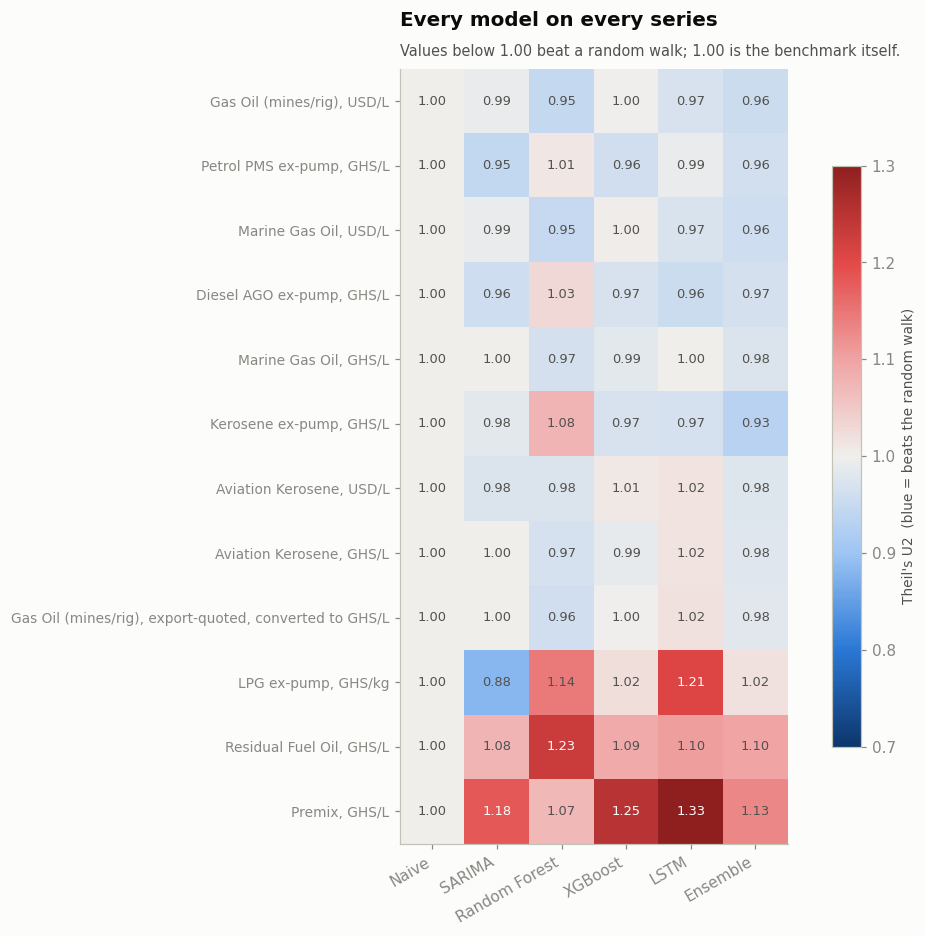

In [39]:
heat = replication.pivot_table(index="series", columns="model", values="Theil U")
heat = heat[[m for m in MODEL_ORDER if m in heat.columns]]
heat = heat.loc[heat.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(9.4, 0.52 * len(heat) + 2.4))
im = ax.imshow(heat.values, cmap=viz.DIVERGING, vmin=0.7, vmax=1.3)
ax.set_xticks(range(len(heat.columns))); ax.set_xticklabels(heat.columns, rotation=30, ha="right")
ax.set_yticks(range(len(heat.index))); ax.set_yticklabels(heat.index, fontsize=9)
for i in range(len(heat.index)):
    for j in range(len(heat.columns)):
        v = heat.values[i, j]
        if np.isfinite(v):
            ax.text(j, i, "%.2f" % v, ha="center", va="center", fontsize=8.5,
                    color=viz.INK["surface"] if abs(v - 1) > 0.18 else viz.INK["secondary"])
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.75)
cb.set_label("Theil's U2  (blue = beats the random walk)", fontsize=9)
viz.titled(ax, "Every model on every series",
           "Values below 1.00 beat a random walk; 1.00 is the benchmark itself.")
fig.tight_layout()
viz.save_fig(fig, "19_replication_heatmap", FIG_DIR)
plt.show()

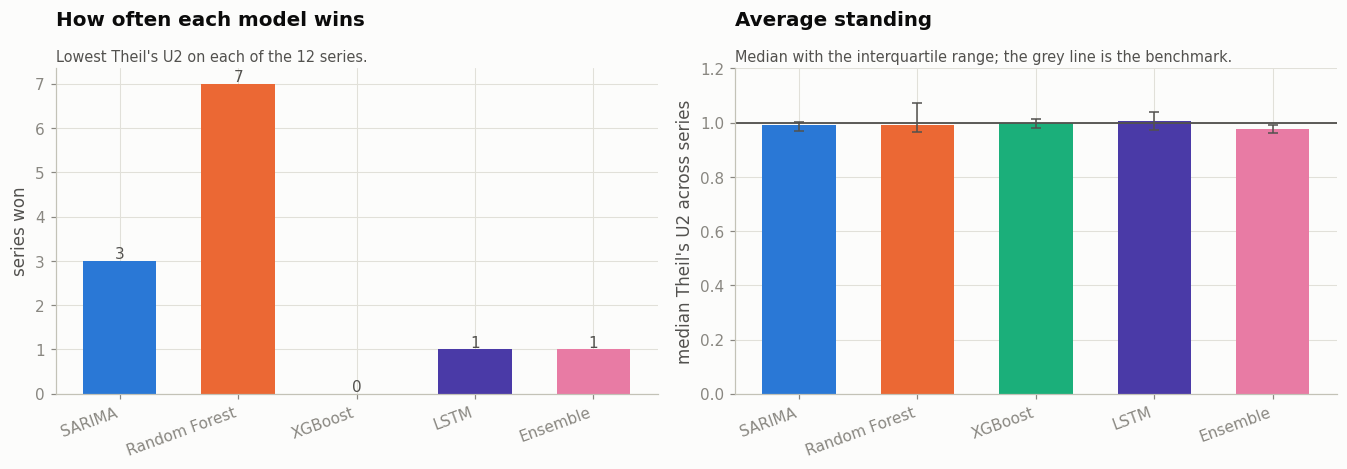

,model,Theil U,MAPE (%)
series,,,
"LPG ex-pump, GHS/kg",SARIMA,0.8800,3.4390
"Kerosene ex-pump, GHS/L",Ensemble,0.9330,3.3640
"Petrol PMS ex-pump, GHS/L",SARIMA,0.9460,3.6500
"Gas Oil (mines/rig), USD/L",Random Forest,0.9480,6.6280
"Marine Gas Oil, USD/L",Random Forest,0.9500,6.6200
"Diesel AGO ex-pump, GHS/L",LSTM,0.9570,3.3630
"Gas Oil (mines/rig), export-quoted, converted to GHS/L",Random Forest,0.9620,9.5580
"Marine Gas Oil, GHS/L",Random Forest,0.9670,9.5580
"Aviation Kerosene, GHS/L",Random Forest,0.9670,10.0270


In [40]:
wins = (replication[replication["model"] != "Naive"]
        .loc[lambda d: d.groupby("series")["Theil U"].idxmin(), ["series", "model", "Theil U", "MAPE (%)"]]
        .sort_values("Theil U"))
counts = wins["model"].value_counts().reindex(
    [m for m in MODEL_ORDER if m not in ("Naive", "Seasonal Naive")]).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
ax = axes[0]
ax.bar(range(len(counts)), counts.values,
       color=[viz.MODEL_COLORS[m] for m in counts.index], width=0.62)
for i, v in enumerate(counts.values):
    ax.text(i, v + 0.06, "%d" % v, ha="center", fontsize=10, color=viz.INK["secondary"])
ax.set_xticks(range(len(counts))); ax.set_xticklabels(counts.index, rotation=20, ha="right")
ax.set_ylabel("series won")
viz.titled(ax, "How often each model wins", "Lowest Theil's U2 on each of the %d series." % len(wins))

ax = axes[1]
# The median, not the mean: one pathological series (Premix, whose price is a
# step function with long flat stretches) sends XGBoost's mean past 2 and would
# otherwise decide the ranking on its own. Bars show the median, whiskers the
# interquartile range across series.
stand = (replication[replication["model"] != "Naive"]
         .groupby("model")["Theil U"].agg(median="median",
                                          q1=lambda s: s.quantile(0.25),
                                          q3=lambda s: s.quantile(0.75)))
stand = stand.reindex([m for m in MODEL_ORDER if m in stand.index])
ax.axhline(1.0, color=viz.INK["secondary"], linewidth=1.2)
ax.bar(range(len(stand)), stand["median"],
       color=[viz.MODEL_COLORS[m] for m in stand.index], width=0.62)
ax.errorbar(range(len(stand)), stand["median"],
            yerr=[stand["median"] - stand["q1"], stand["q3"] - stand["median"]],
            fmt="none", ecolor=viz.INK["secondary"], elinewidth=1.0, capsize=3)
ax.set_xticks(range(len(stand))); ax.set_xticklabels(stand.index, rotation=20, ha="right")
ax.set_ylabel("median Theil's U2 across series")
ax.set_ylim(0, max(1.15, float(stand["q3"].max()) * 1.12))
viz.titled(ax, "Average standing",
           "Median with the interquartile range; the grey line is the benchmark.")
fig.tight_layout()
viz.save_fig(fig, "20_model_standings", FIG_DIR)
plt.show()

wins.set_index("series").round(3)

## 15. Ex-ante forecast

The models are now refitted on the **entire** sample and projected 12 months
past the last observation. The exogenous drivers are held at their final
observed value over the horizon - the honest assumption when no independent
forecast of the cedi or of world product prices is available, and one that
should be stated wherever this projection is quoted.

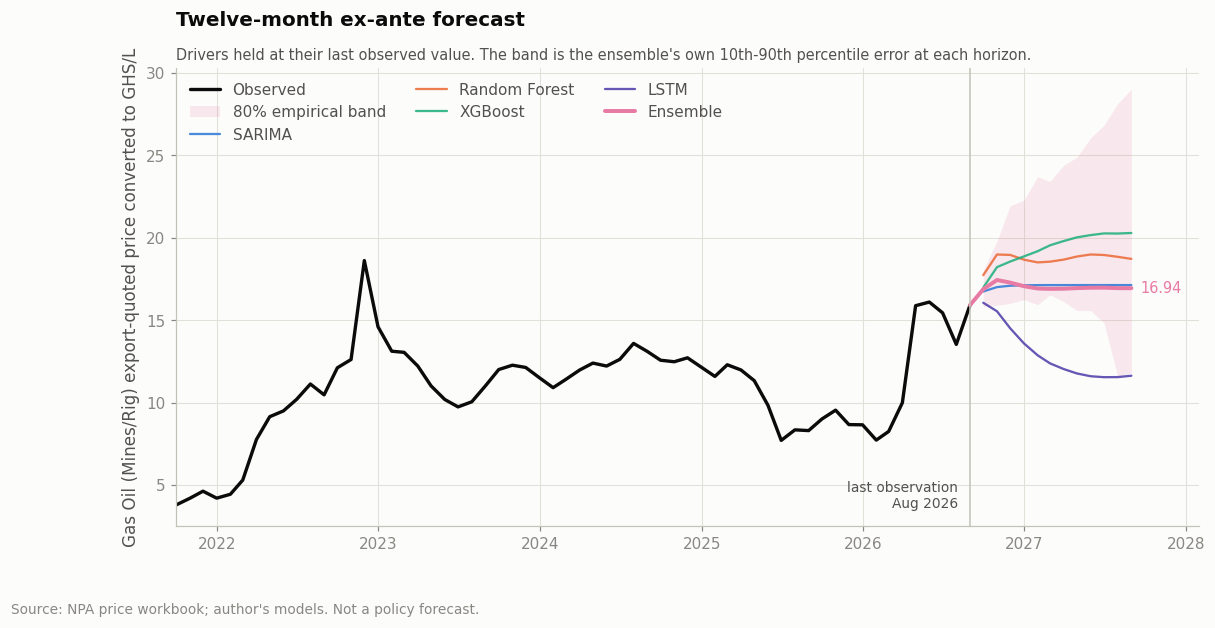

,SARIMA,Random Forest,XGBoost,LSTM,Ensemble,lower,upper
2026-09-30,16.7400,17.7310,16.9770,16.0560,16.8760,15.8320,18.0300
2026-10-31,17.0070,18.9830,18.2180,15.5410,17.4370,15.9020,19.7880
2026-11-30,17.0910,18.9600,18.5580,14.5040,17.2780,16.0170,21.9540
2026-12-31,17.1170,18.6710,18.8690,13.5910,17.0620,16.2490,22.2730
2027-01-31,17.1250,18.5050,19.1850,12.8690,16.9210,15.9380,23.7040
2027-02-28,17.1280,18.5500,19.5430,12.3790,16.9000,16.5380,23.4190
2027-03-31,17.1280,18.6750,19.8020,12.0320,16.9090,16.1220,24.4000
2027-04-30,17.1290,18.8630,20.0260,11.7650,16.9460,15.5900,24.8930
2027-05-31,17.1290,18.9860,20.1630,11.5970,16.9680,15.5790,26.0550
2027-06-30,17.1290,18.9560,20.2640,11.5400,16.9720,14.8440,26.8260


In [41]:
future_index = pd.date_range(data.index[-1] + pd.offsets.MonthEnd(1),
                             periods=MAX_HORIZON, freq="ME")

full_feats = fc.make_features(data, spec).dropna()
X_full = full_feats[FEATURES]
r_full = full_feats["r"]

rf_full = RandomForestRegressor(**{**rf_search.best_params_, "random_state": RANDOM_STATE,
                                   "n_jobs": -1}).fit(X_full, r_full)
xgb_full = xgb.XGBRegressor(**{**xgb_search.best_params_, "random_state": RANDOM_STATE,
                               "n_jobs": -1, "tree_method": "hist"}).fit(X_full, r_full)
lstm_full = fc.LSTMRegressor(window=12, hidden=48, layers=2, epochs=400,
                             n_seeds=5, verbose=False).fit(X_full, r_full)

future = pd.DataFrame(index=future_index)
future["Random Forest"] = fc.recursive_forecast(
    data, future_index, spec, lambda z, c: rf_full.predict(z), columns=FEATURES)
future["XGBoost"] = fc.recursive_forecast(
    data, future_index, spec, lambda z, c: xgb_full.predict(z), columns=FEATURES)
future["LSTM"] = fc.recursive_forecast(
    data, future_index, spec, lambda z, c: lstm_full.predict(z, context=c), columns=FEATURES)

sar_full = fc.fit_sarimax(np.log(y), SARIMA_ORDER, SARIMA_SEASONAL)
sf = sar_full.get_forecast(steps=MAX_HORIZON)
future["SARIMA"] = np.exp(sf.predicted_mean).values
sar_ci = np.exp(sf.conf_int(alpha=0.20)); sar_ci.index = future_index
future["Ensemble"] = future[["SARIMA", "Random Forest", "XGBoost", "LSTM"]].mean(axis=1)

# Empirical uncertainty band: the spread of hold-out errors at each horizon,
# which reflects how this ensemble has actually behaved rather than an assumption.
ens_mh = mh.assign(err_pct=lambda d: (d["Ensemble"] - d["actual"]) / d["actual"])
band = ens_mh.groupby("h")["err_pct"].quantile([0.10, 0.90]).unstack()
band.columns = ["q10", "q90"]
future["lower"] = future["Ensemble"] * (1 + band["q10"].reindex(range(1, MAX_HORIZON + 1)).values)
future["upper"] = future["Ensemble"] * (1 + band["q90"].reindex(range(1, MAX_HORIZON + 1)).values)
future.round(3).to_csv(TBL_DIR / "ex_ante_forecast.csv")

fig, ax = plt.subplots(figsize=(12, 5.4))
hist_tail = y.loc[y.index >= y.index[-60]]
ax.plot(hist_tail.index, hist_tail.values, color=viz.INK["primary"], linewidth=2.2, label="Observed")
ax.fill_between(future_index, future["lower"], future["upper"],
                color=viz.CATEGORICAL[4], alpha=0.16, linewidth=0,
                label="80% empirical band")
for m in ["SARIMA", "Random Forest", "XGBoost", "LSTM"]:
    ax.plot(future_index, future[m], color=viz.MODEL_COLORS[m], linewidth=1.5,
            alpha=0.85, label=m)
ax.plot(future_index, future["Ensemble"], color=viz.MODEL_COLORS["Ensemble"],
        linewidth=2.6, label="Ensemble")
ax.plot([hist_tail.index[-1], future_index[0]],
        [hist_tail.iloc[-1], future["Ensemble"].iloc[0]],
        color=viz.MODEL_COLORS["Ensemble"], linewidth=2.6)
ax.axvline(y.index[-1], color=viz.INK["axis"], linewidth=1.0)
ax.annotate("last observation\n%s" % y.index[-1].strftime("%b %Y"),
            xy=(y.index[-1], ax.get_ylim()[0]), xytext=(-8, 12),
            textcoords="offset points", ha="right", fontsize=9, color=viz.INK["secondary"])
viz.label_end(ax, future_index[-1], future["Ensemble"].iloc[-1],
              "%.2f" % future["Ensemble"].iloc[-1], viz.MODEL_COLORS["Ensemble"])
ax.set_xlim(hist_tail.index[0], future_index[-1] + pd.DateOffset(months=5))
ax.set_ylabel(TARGET_LABEL)
ax.legend(loc="upper left", ncol=3)
viz.titled(ax, "Twelve-month ex-ante forecast",
           "Drivers held at their last observed value. The band is the ensemble's own "
           "10th-90th percentile error at each horizon.")
viz.annotate_source(fig, "Source: NPA price workbook; author's models. Not a policy forecast.")
viz.save_fig(fig, "21_ex_ante_forecast", FIG_DIR)
plt.show()

future[["SARIMA", "Random Forest", "XGBoost", "LSTM", "Ensemble", "lower", "upper"]].round(3)

## 16. Summary

### 16.1 Computational cost

Accuracy is not the only axis a thesis should report: a model that takes two
orders of magnitude longer to fit for a fractional gain is a different
proposition for a regulator running it monthly.

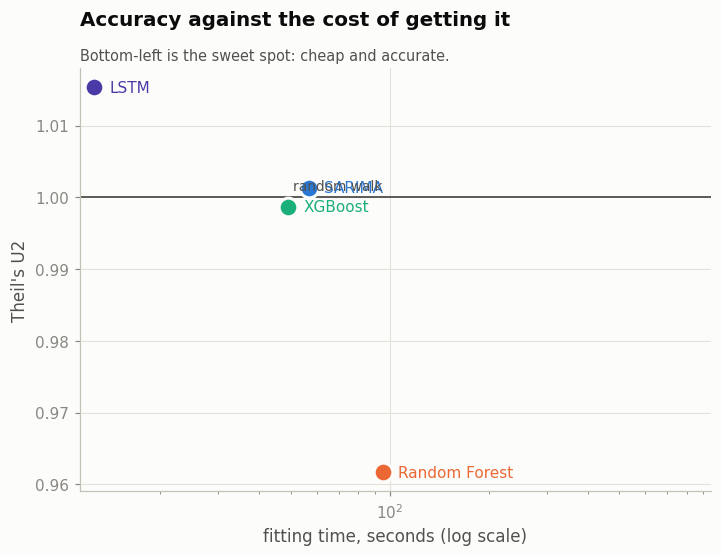

,fit seconds,RMSE,MAPE (%),Theil U
LSTM,12.6020,1.6110,10.1090,1.0150
Random Forest,95.1330,1.5140,9.5580,0.9620
SARIMA,56.7750,1.5740,9.6470,1.0010
XGBoost,49.0090,1.5730,9.5020,0.9990


In [42]:
cost = pd.DataFrame({
    "fit seconds": pd.Series(fit_seconds),
    "RMSE": results["RMSE"],
    "MAPE (%)": results["MAPE (%)"],
    "Theil U": results["Theil U"],
}).dropna(subset=["fit seconds"])

fig, ax = plt.subplots(figsize=(7.4, 5))
for m in cost.index:
    ax.scatter(cost.loc[m, "fit seconds"], cost.loc[m, "Theil U"], s=150,
               color=viz.MODEL_COLORS[m], edgecolor=viz.INK["surface"], linewidth=2, zorder=3)
    ax.annotate(m, xy=(cost.loc[m, "fit seconds"], cost.loc[m, "Theil U"]),
                xytext=(10, 0), textcoords="offset points", fontsize=10,
                color=viz.MODEL_COLORS[m], va="center")
ax.axhline(1.0, color=viz.INK["secondary"], linewidth=1.2)
ax.annotate("random walk", xy=(ax.get_xlim()[1], 1.0), xytext=(-4, 5),
            textcoords="offset points", ha="right", fontsize=9, color=viz.INK["secondary"])
ax.set_xscale("log")
ax.set_xlabel("fitting time, seconds (log scale)")
ax.set_ylabel("Theil's U2")
ax.set_xlim(right=ax.get_xlim()[1] * 9)   # headroom so the rightmost label fits
viz.titled(ax, "Accuracy against the cost of getting it",
           "Bottom-left is the sweet spot: cheap and accurate.")
viz.save_fig(fig, "22_cost_vs_accuracy", FIG_DIR)
plt.show()

cost.round(3)

### 16.2 Findings

In [43]:
lines = []
lines.append("PRIMARY SERIES : %s" % SERIES_LABELS.get(PRIMARY_TARGET, PRIMARY_TARGET))
lines.append("SAMPLE         : %s - %s (%d months, %d used after feature warm-up)"
             % (y.index[0].strftime("%b %Y"), y.index[-1].strftime("%b %Y"), len(y), len(feats)))
lines.append("HOLD-OUT       : %d months, never trained on" % TEST_MONTHS)
lines.append("")
lines.append("ONE STEP AHEAD")
lines.append("  best RMSE            %-16s %.4f" % (best_rmse, results.loc[best_rmse, "RMSE"]))
lines.append("  best MAPE            %-16s %.2f%%"
             % (results["MAPE (%)"].idxmin(), results["MAPE (%)"].min()))
lines.append("  best direction       %-16s %.1f%%"
             % (results["Dir. Acc (%)"].idxmax(), results["Dir. Acc (%)"].max()))
lines.append("  beat the random walk %s"
             % (", ".join(m for m in beat_rw if m != "Naive") or "none"))
lines.append("")
lines.append("ACROSS HORIZONS 1-%d" % MAX_HORIZON)
for h in (1, 3, 6, MAX_HORIZON):
    if h in prof.index:
        us = {m: prof.loc[h, m + "|U"] for m in mh_models}
        bm_u = min(us, key=us.get)
        mapes = {m: prof.loc[h, m + "|MAPE"] for m in mh_models}
        bm_mape = min(mapes, key=mapes.get)
        lines.append("  h=%-2d  lowest U2 %-12s %.3f; lowest MAPE %-12s %.2f%%"
                     % (h, bm_u, us[bm_u], bm_mape, mapes[bm_mape]))
lines.append("")
lines.append("ACROSS %d PRODUCT SERIES" % replication["series"].nunique())
for m, n in counts.items():
    lines.append("  %-16s won %d series" % (m, int(n)))
lines.append("")
lines.append("SEASONALITY    : strength %.2f - %s"
             % (seas_strength, "material" if seas_strength > 0.4 else "negligible; the selected SARIMA order reflects that"))
lines.append("STATIONARITY   : levels carry a unit root, first differences do not")
lines.append("                 -> d = 1 for SARIMA; returns as the learner target")

report = "\n".join(lines)
print(report)
(TBL_DIR / "summary.txt").write_text(report, encoding="utf-8")

PRIMARY SERIES : Gas Oil (mines/rig), export-quoted, converted to GHS/L
SAMPLE         : Jan 2011 - Aug 2026 (188 months, 175 used after feature warm-up)
HOLD-OUT       : 24 months, never trained on

ONE STEP AHEAD
  best RMSE            Random Forest    1.5144
  best MAPE            Naive            8.87%
  best direction       Seasonal Naive   50.0%
  beat the random walk Random Forest, XGBoost, Ensemble

ACROSS HORIZONS 1-12
  h=1   lowest U2 SARIMA       0.945; lowest MAPE SARIMA       5.47%
  h=3   lowest U2 Naive        1.000; lowest MAPE SARIMA       11.05%
  h=6   lowest U2 Naive        1.000; lowest MAPE Naive        14.89%
  h=12  lowest U2 Naive        1.000; lowest MAPE Naive        29.01%

ACROSS 12 PRODUCT SERIES
  SARIMA           won 3 series
  Random Forest    won 7 series
  XGBoost          won 0 series
  LSTM             won 1 series
  Ensemble         won 1 series

SEASONALITY    : strength 0.08 - negligible; the selected SARIMA order reflects that
STATIONARITY   : 

1118

### 16.3 Outputs written

Figures are written twice: a 300 dpi PNG for drafts and a vector PDF for the
typeset thesis.

In [44]:
figs = sorted(p.name for p in FIG_DIR.glob("*.png"))
tbls = sorted(p.name for p in TBL_DIR.glob("*"))
print("outputs/figures/  (%d)" % len(figs))
for f in figs:
    print("   ", f)
print("\noutputs/tables/   (%d)" % len(tbls))
for t in tbls:
    print("   ", t)

outputs/figures/  (22)
    01_long_run_prices.png
    02_primary_series.png
    03_fx_passthrough.png
    04_pricing_formula.png
    05_stl_decomposition.png
    06_acf_pacf.png
    07_volatility_distribution.png
    08_seasonality.png
    09_correlation_matrix.png
    10_train_test_split.png
    11_sarima_diagnostics.png
    12_rf_importance.png
    13_xgb_importance.png
    14_lstm_training.png
    15_forecasts_vs_actual.png
    16_error_distribution.png
    17_diebold_mariano.png
    18_horizon_profile.png
    19_replication_heatmap.png
    20_model_standings.png
    21_ex_ante_forecast.png
    22_cost_vs_accuracy.png

outputs/tables/   (11)
    data_quality_audit.csv
    diebold_mariano_pvalues.csv
    ex_ante_forecast.csv
    headline_metrics.csv
    headline_metrics.tex
    multi_horizon_profile.csv
    replication_all_series.csv
    rf_feature_importance.csv
    stationarity_tests.csv
    summary.txt
    xgb_feature_importance.csv


---

### Notes for the write-up

* **The random walk is the benchmark that matters.** Reporting R2 against a
  trending price level flatters every model; MASE and Theil's U2 are reported
  here precisely because they cannot be inflated that way. Where a model does
  not beat the random walk one step ahead, say so - it is a finding about the
  efficiency of Ghana's pricing windows, not a defect in the model.

* **State the exogenous assumption** wherever the ex-ante forecast appears:
  the cedi and world product prices are held at their last observed value, so
  the projection is conditional, not unconditional.

* **Two datasets in the proposal are absent** from this repository - the NPA
  consumption volumes and the GSS monthly CPI. Section 1.1 records that
  explicitly. Once obtained they merge on the month index and every cell below
  re-runs unchanged.

* **Reproducibility.** Every random process is seeded (`RANDOM_STATE = 42`);
  the LSTM additionally averages five seeds so its result does not depend on
  one initialisation.